# Imports

## Import the folder for compatibility (if running local)

In [ ]:
import os
import sys

project_root = "Incremental-Learning-MycroftMinds"
cwd = os.path.abspath(os.getcwd())
while True:
    if os.path.basename(cwd) == project_root:
        if cwd not in sys.path:
            sys.path.insert(0, cwd)
        break
    parent = os.path.dirname(cwd)
    if parent == cwd:
        raise FileNotFoundError(f"Project root '{project_root}' not found in any parent directory.")
    cwd = parent

## Import external libs and internal models

In [2]:
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from tqdm.notebook import tqdm

from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from river.forest import ARFRegressor
#from river.ensemble import BaggingRegressor, SRPRegressor
from river.tree import HoeffdingTreeRegressor, HoeffdingAdaptiveTreeRegressor
#from river.drift.binary import DDM, EDDM
from src.bagging import ARFRegressorFODT
from src.evaluation.baseline import PreviousValueRegressor
from src.trees import fastodt
from src.boosting import IncubationBoost
from src.ensemble_methods import elasticGBDT

from src.data.io import load_dataset
from src.utils.memory import calculate_memory_usage
from src.evaluation.metrics import all_time_aggregation_metrics
from src.evaluation.visualization import plot_part_predictions, plot_hourly_predictions
from src.evaluation.training import all_valid_splits_seq_fit_predict, test_set_seq_fit_predict


import ipywidgets as widgets
widgets.IntSlider()

IntSlider(value=0)

# Download the splitted data

In [3]:
# check you data dir and file prefixes
data_dir = '../data/first_batch'

## Pick the hourly or 5-min granularity data
- WFV, train+=28 (train set increasing), validation=28, hourly granularity
- WFV, train+=28 (train set increasing), validation=28, 5-min granularity

In [4]:
HOURLY = True
DATA_FREQUENCY = 'H' if HOURLY else '5min'

In [5]:
# Measure loading time
start_time = time.time()

# Load data
if HOURLY:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='dev_4_hourly_wfv', use_numpy=True)
    features = ['time', 'device_id', 'hour', 'weekday', 'month', 
                 'L1_act_power_lag_1h', 'L1_act_power_lag_24h', 'L1_app_power_lag_1h', 'L1_app_power_lag_24h', 
                 'L1_current_lag_1h', 'L1_current_lag_24h', 'L1_react_power_lag_1h', 'L1_react_power_lag_24h', 
                 'L1_voltage_lag_1h', 'L1_voltage_lag_24h', 
                 'L2_act_power_lag_1h', 'L2_act_power_lag_24h', 'L2_app_power_lag_1h', 'L2_app_power_lag_24h', 
                 'L2_current_lag_1h', 'L2_current_lag_24h', 'L2_react_power_lag_1h', 'L2_react_power_lag_24h', 
                 'L2_voltage_lag_1h', 'L2_voltage_lag_24h', 
                 'L3_act_power_lag_1h', 'L3_act_power_lag_24h', 'L3_app_power_lag_1h', 'L3_app_power_lag_24h', 
                 'L3_current_lag_1h', 'L3_current_lag_24h', 'L3_react_power_lag_1h', 'L3_react_power_lag_24h', 
                 'L3_voltage_lag_1h', 'L3_voltage_lag_24h', 
                 'grid_freq_lag_1h', 'grid_freq_lag_24h', 
                 'powerfactor1_lag_1h', 'powerfactor1_lag_24h', 
                 'powerfactor2_lag_1h', 'powerfactor2_lag_24h', 
                 'powerfactor3_lag_1h', 'powerfactor3_lag_24h']
else:
    train, valid, test = load_dataset(data_dir=data_dir, prefix='8_dev_5_min_wfv', use_numpy=True)
    # copy features from dataloader printouts
    features = []

loading_time = time.time() - start_time
print(f"Data loaded in {loading_time/60:.2f} minutes")

[INFO] Loading train data...
[INFO] Train data loaded: 7 samples
[INFO] Loading valid data...
[INFO] Valid data loaded: 7 samples
[INFO] Loading test data...
[INFO] Test data loaded: 2 samples
Data loaded in 0.00 minutes


## Data structure information

The data structure is as follows:
- For walk-forward validation:
  - `train` is a list of tuples, where each tuple is (X, y) for one split
  - `valid` is a list of tuples, where each tuple is (X, y) for one split
  - `test` is a tuple of (X, y)
- Each X array contains:
  - Column 0: `time` (`pandas.Timedelta`)
  - Column 1: `device_id` (`str`)
  - Other columns: time-related features and lag features

The memory usage of the loaded data is printed below:

In [6]:
# Print data structure and memory usage information
if isinstance(train, list):
    print(f"Training data: {len(train)} splits")
    print(f"Validation data: {len(valid)} splits")
    
    # Show first split shape
    print(f"First train split shape: X={train[0][0].shape}, y={train[0][1].shape}")
    print(f"First valid split shape: X={valid[0][0].shape}, y={valid[0][1].shape}")
    
    # Memory usage
    train_mem = sum(calculate_memory_usage(ts) for ts in train)
    valid_mem = sum(calculate_memory_usage(vs) for vs in valid)
    test_mem = calculate_memory_usage(test)
    
    print(f"\nMemory usage:")
    print(f"Train: {train_mem:.2f} MB")
    print(f"Valid: {valid_mem:.2f} MB")
    print(f"Test: {test_mem:.2f} MB")
    print(f"Total: {train_mem + valid_mem + test_mem:.2f} MB")
else:
    # For non-list structure
    print(f"Training data shape: X={train[0].shape}, y={train[1].shape}")
    print(f"Validation data shape: X={valid[0].shape}, y={valid[1].shape}")
    print(f"Test data shape: X={test[0].shape}, y={test[1].shape}")

Training data: 7 splits
Validation data: 7 splits
First train split shape: X=(649, 43), y=(649,)
First valid split shape: X=(672, 43), y=(672,)

Memory usage:
Train: 6.26 MB
Valid: 1.41 MB
Test: 0.41 MB
Total: 8.08 MB


# WFV Model Evaluation
(train+valid WFV)
- (1) `train[0]` vs `valid[0]`
- (2) `train[1]` vs `valid[1]`
- ...
- (n) `train[n]` vs `valid[n]`

, where: 
$$ train[1] = train[0]+valid[0] $$
$$...$$
$$ train[n] = train[0]+valid[0]+valid[1]+...+valid[n-1] $$

## Hourly granularity

### Baseline model (predict previous value)

In [7]:
update_freq = "1H"
baseline = PreviousValueRegressor()

In [8]:
baseline_train_period_predictions, baseline_valid_period_predictions,\
baseline_train_period_metrics, baseline_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=baseline,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2535
	MAE: 0.1477
	MAPE: 17.4044%

Directional Metrics:
	Directional Accuracy: 36.0656%
	First-Diff Correlation: -0.0202

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3479
	MAE: 0.

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2578
	MAE: 0.1454
	MAPE: 23.4458%

Directional Metrics:
	Directional Accuracy: 38.3010%
	First-Diff Correlation: 0.2243

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3271
	MAE: 0.1

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2448
	MAE: 0.1448
	MAPE: 31.0642%

Directional Metrics:
	Directional Accuracy: 37.4069%
	First-Diff Correlation: -0.0210

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2440
	MAE: 0.

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1543
	MAE: 0.0696
	MAPE: 12.5644%

Directional Metrics:
	Directional Accuracy: 40.1274%
	First-Diff Correlation: 0.4616

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.7500
		Recall: 1.0000
		F1: 0.8571
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1261
	MAE: 0.0

#### Results

In [9]:
print("\n\nValid period metrics:")
baseline_all_time_valid_metrics = all_time_aggregation_metrics(baseline_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Valid period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2280 ± 0.0407
	MAE: 0.1290 ± 0.0296
	MAPE: 23.9570% ± 7.3836%

	Directional Metrics:
		Directional Accuracy: 39.3923% ± 4.6442%
		First-Diff Correlation: 0.1838 ± 0.1970

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.8571 ± 0.3499
		Spike Recall: 0.8571 ± 0.3499
		Spike F1: 0.8571 ± 0.3499
		Drop Precision: 0.8139 ± 0.3429
		Drop Recall: 0.8571 ± 0.3499
		Drop F1: 0.8329 ± 0.3434
Daily Metrics:
	RMSE: 0.2624 ± 0.0673
	MAE: 0.1164 ± 0.0326
	MAPE: 1.3658% ± 0.2072%

	Directional Metrics:
		Directional Accuracy: 95.9184% ± 3.5348%
		First-Diff Correlation: 0.9995 ± 0.0003

	Immediate Detection (delta=0):


#### Validation plots

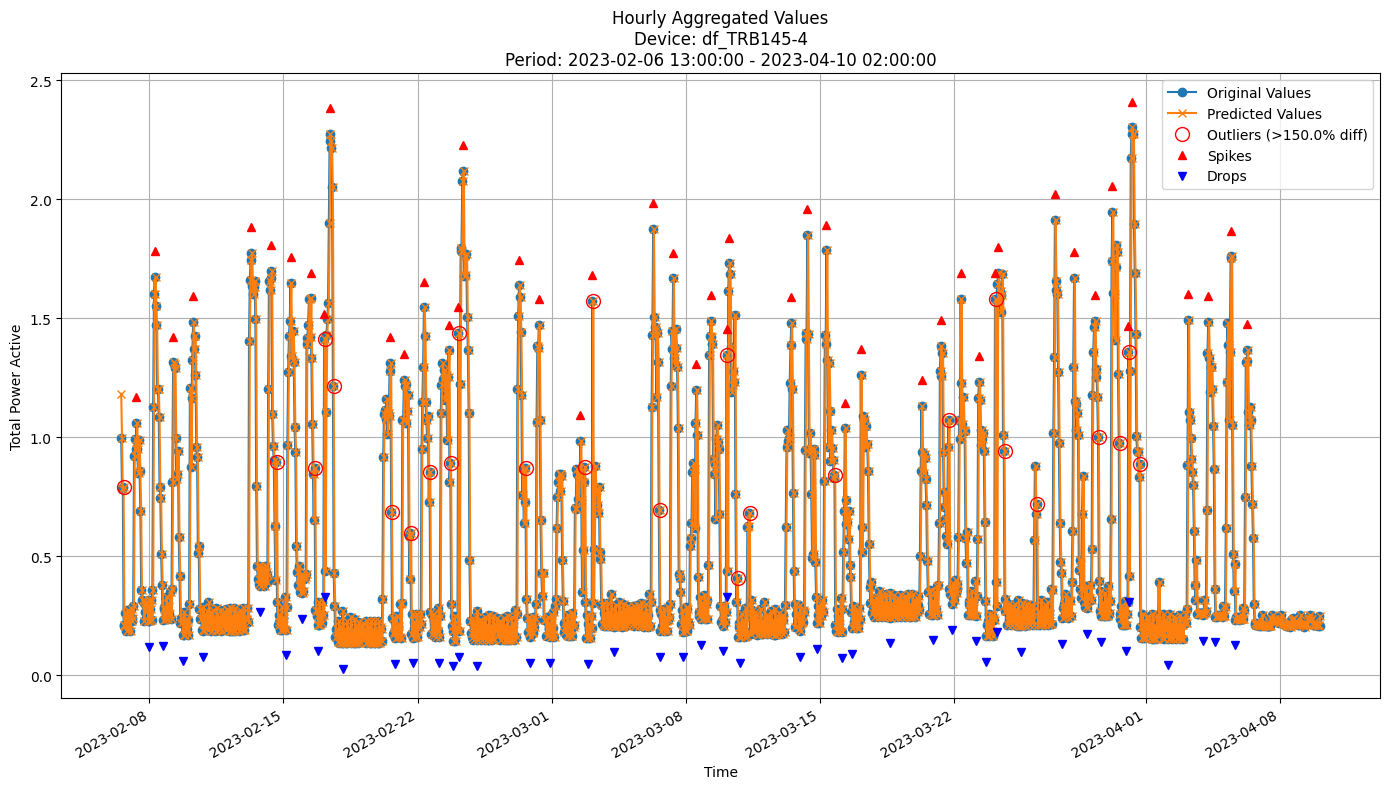


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2328
MAE: 0.1326
MAPE: 29.8567%

Directional Metrics:
Directional Accuracy: 36.8421%
First-Diff Correlation: -0.0120

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 1.0000
  Recall: 1.0000
  F1 Score: 1.0000
Drops:
  Precision: 0.9787
  Recall: 1.0000
  F1 Score: 0.9892


In [10]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in baseline_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, baseline_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, baseline_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5,
                            )

### GBDT

In [11]:
update_freq = "14D"  # Update the model every 14 days
gbdt = GradientBoostingRegressor(
    n_estimators=50,
    learning_rate=0.05,
    subsample=0.6,
    max_depth=3,
    random_state=42)

# RMSE (best: 0.230)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 0.8, 'random_state': 42}
# MAE (best: 0.143)
#     Parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 1.0, 'random_state': 42}
# MAPE (best: 28.070%)
#     Parameters: {'n_estimators': 100, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 1.0, 'random_state': 42}
# DIR_ACCURACY (best: 62.673%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 12, 'subsample': 0.8, 'random_state': 42}
# FIRST_DIFF_CORR (best: 42.984%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.05, 'max_depth': 3, 'subsample': 0.6, 'random_state': 42}
# SPIKES_F1 (best: 20.873%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.1, 'max_depth': 3, 'subsample': 0.6, 'random_state': 42}
# DROPS_F1 (best: 15.373%)
#     Parameters: {'n_estimators': 50, 'learning_rate': 0.15, 'max_depth': 15, 'subsample': 0.8, 'random_state': 42}


In [12]:
gbdt_train_period_predictions, gbdt_valid_period_predictions, \
gbdt_train_period_metrics, gbdt_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=gbdt, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00

Time: 0.21 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-10-17 13:00:00 to 2022-10-31 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-10-31 13:00:00

Time: 0.28 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-10-31 14:00:00 to 2022-11-14 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3396
	MAE: 0.2195
	MAPE: 24.9436%

Directional Metrics:
	Directional Accuracy: 52.3100%
	First-Diff Correlation: 0.2661

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00

Time: 0.37 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-11-14 13:00:00 to 2022-11-28 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-28 13:00:00

Time: 0.48 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-11-28 14:00:00 to 2022-12-12 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2912
	MAE: 0.1965
	MAPE: 35.8593%

Directional Metrics:
	Directional Accuracy: 50.6706%
	First-Diff Correlation: 0.3805

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00

Time: 1.19 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-03-06 13:00:00 to 2023-03-20 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-20 13:00:00

Time: 1.33 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-03-20 14:00:00 to 2023-04-03 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2237
	MAE: 0.1468
	MAPE: 34.6536%

Directional Metrics:
	Directional Accuracy: 51.5648%
	First-Diff Correlation: 0.3442

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0476
		Recall: 0.1000
		F1: 0.0645


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00

Time: 1.42 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-04-03 13:00:00 to 2023-04-10 02:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1644
	MAE: 0.1098
	MAPE: 32.1299%

Directional Metrics:
	Directional Accuracy: 41.4013%
	First-Diff Correlation: 0.3578

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2500
		Recall: 0.2500
		F1: 0.2500
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
---------------------------------------

#### Results

In [13]:
print("\n\nTrain period metrics:")
gbdt_all_time_train_metrics = all_time_aggregation_metrics(gbdt_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
gbdt_all_time_valid_metrics = all_time_aggregation_metrics(gbdt_valid_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# Hourly Metrics:
# 	RMSE: 0.2486 ± 0.0612
# 	MAE: 0.1594 ± 0.0516
# 	MAPE: 33.4958% ± 5.3587%

# 	Directional Metrics:
# 		Directional Accuracy: 62.4754% ± 7.1041%
# 		First-Diff Correlation: 0.3821 ± 0.0970

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.1544 ± 0.1193
# 		Spike Recall: 0.1617 ± 0.1297
# 		Spike F1: 0.1577 ± 0.1238
# 		Drop Precision: 0.1459 ± 0.0857
# 		Drop Recall: 0.1534 ± 0.0909
# 		Drop F1: 0.1493 ± 0.0879

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4691 ± 0.2714
# 		Spike Recall: 0.4908 ± 0.2907
# 		Spike F1: 0.4788 ± 0.2795
# 		Drop Precision: 0.2117 ± 0.1062
# 		Drop Recall: 0.2201 ± 0.1161
# 		Drop F1: 0.2153 ± 0.1100



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2141 ± 0.0136
	MAE: 0.1306 ± 0.0094
	MAPE: 25.0931% ± 2.1436%

	Directional Metrics:
		Directional Accuracy: 60.6070% ± 1.6260%
		First-Diff Correlation: 0.5197 ± 0.0522

	Immediate Detection (delta=0):
		Spike Precision: 0.0511 ± 0.0840
		Spike Recall: 0.0463 ± 0.0800
		Spike F1: 0.0484 ± 0.0815
		Drop Precision: 0.0363 ± 0.0449
		Drop Recall: 0.0486 ± 0.0689
		Drop F1: 0.0341 ± 0.0440

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.2244 ± 0.2625
		Spike Recall: 0.1407 ± 0.2255
		Spike F1: 0.1511 ± 0.2307
		Drop Precision: 0.0535 ± 0.0676
		Drop Recall: 0.0843 ± 0.1280
		Drop F1: 0.0571 ± 0.0836
Daily Metrics:
	RMSE: 1.9125 ± 0.1843
	MAE: 1.5030 ± 0.1615
	MAPE: 12.5622% ± 0.9382%

	Directional Metrics:
		Directional Accuracy: 87.9470% ± 3.6588%
		First-Diff Correlation: 0.9825 ± 0.0018

	Immediate Detection (delta=0):

#### Feature importance
[WiP] Right now only for the last split and last device

In [14]:
feat_imps = sorted(
    zip(features[2:], gbdt.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', np.float64(0.44313091085992806)),
 ('L2_current_lag_1h', np.float64(0.12955371437239005)),
 ('L2_act_power_lag_1h', np.float64(0.12492818922782666)),
 ('hour', np.float64(0.10832741644334591)),
 ('powerfactor3_lag_1h', np.float64(0.051786890723032296)),
 ('L3_react_power_lag_1h', np.float64(0.03177608664512609)),
 ('L1_app_power_lag_1h', np.float64(0.03034625485909974)),
 ('L1_act_power_lag_1h', np.float64(0.019994350940503572)),
 ('L3_act_power_lag_1h', np.float64(0.017569170640895897)),
 ('L2_app_power_lag_1h', np.float64(0.00786733863652199)),
 ('month', np.float64(0.007754883330432001)),
 ('L3_react_power_lag_24h', np.float64(0.0037468880450096317)),
 ('L3_app_power_lag_1h', np.float64(0.00322915219566498)),
 ('L2_app_power_lag_24h', np.float64(0.0030914029920654056)),
 ('L3_app_power_lag_24h', np.float64(0.002452864428855601)),
 ('L3_current_lag_1h', np.float64(0.001852161441169975)),
 ('L1_act_power_lag_24h', np.float64(0.001735627367197002)),
 ('L1_app_pow

#### Training plots

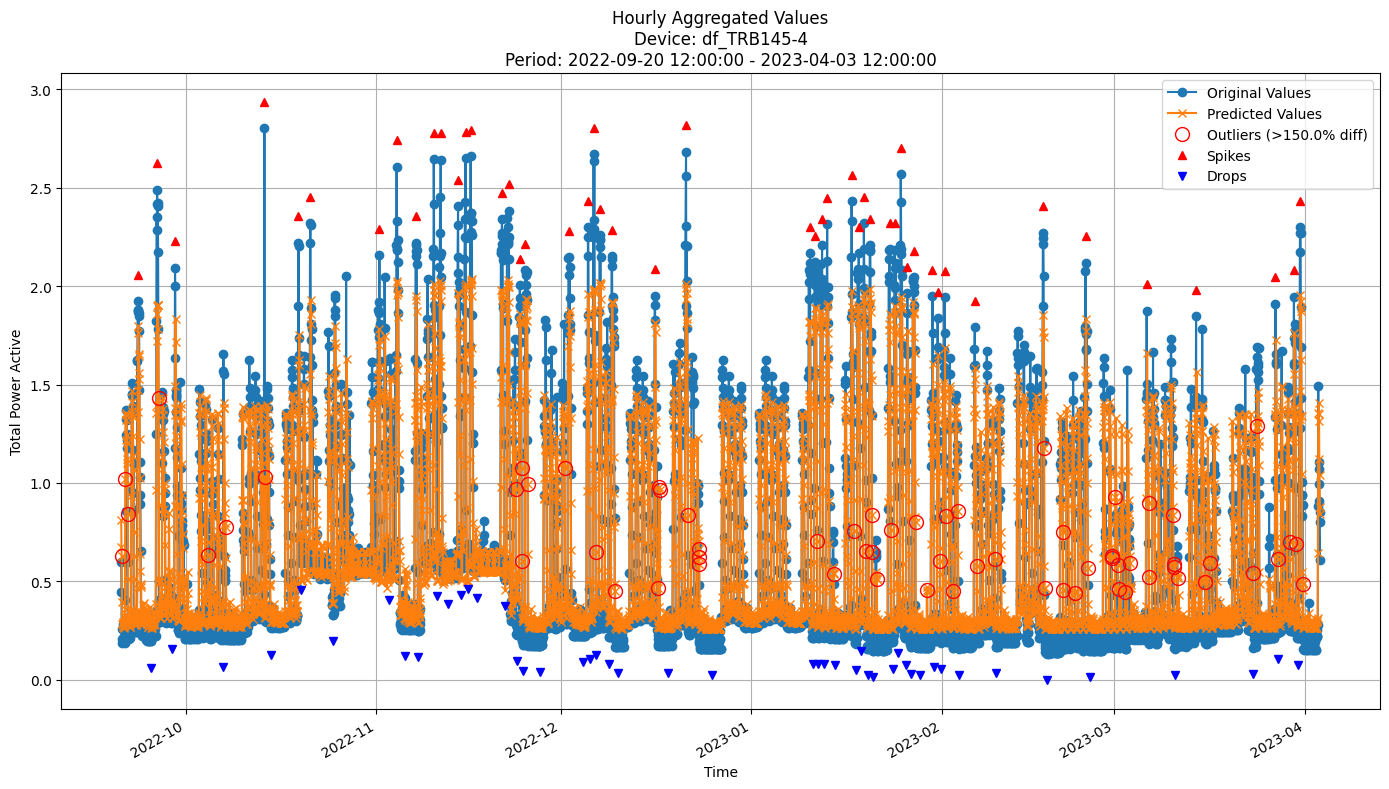


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2203
MAE: 0.1362
MAPE: 28.0304%

Directional Metrics:
Directional Accuracy: 62.3718%
First-Diff Correlation: 0.4848

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1351
  Recall: 0.1020
  F1 Score: 0.1163
Drops:
  Precision: 0.0519
  Recall: 0.1458
  F1 Score: 0.0765

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4595
  Recall: 0.3469
  F1 Score: 0.3953
Drops:
  Precision: 0.0815
  Recall: 0.2292
  F1 Score: 0.1202


In [15]:
for device_id in gbdt_train_period_predictions.keys():
    y_train = gbdt_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = gbdt_train_period_predictions[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)
# 0.17, 0.12, 25.55, 70.81%, 0.72

#### Validation plots
Plot only the last few periods of predictions

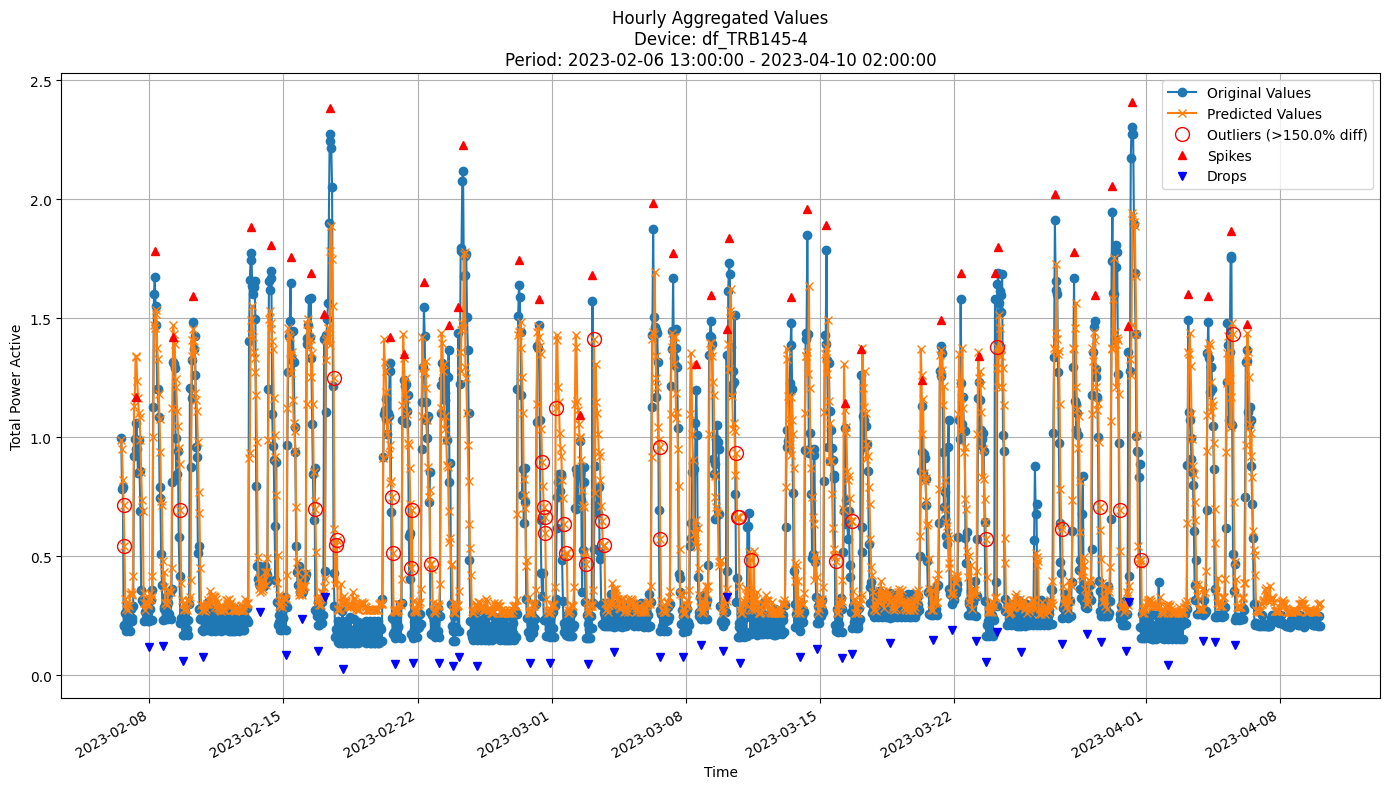


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2190
MAE: 0.1467
MAPE: 38.7525%

Directional Metrics:
Directional Accuracy: 55.4963%
First-Diff Correlation: 0.4169

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0698
  Recall: 0.0638
  F1 Score: 0.0667
Drops:
  Precision: 0.0700
  Recall: 0.1522
  F1 Score: 0.0959

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4419
  Recall: 0.4043
  F1 Score: 0.4222
Drops:
  Precision: 0.1100
  Recall: 0.2391
  F1 Score: 0.1507


In [16]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in gbdt_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, gbdt_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, gbdt_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

# 0.22, 0.15, 39.79, 60.39%, 0.39

### Random Forest model

In [17]:
update_freq = "14D"  # Update the model every 14 days
rf = RandomForestRegressor(
    n_estimators=100, 
    max_depth=10,
    max_features='sqrt',
    random_state=42, 
    n_jobs=-1)

# BEST RMSE: 0.230
#    Best Parameters: {'n_estimators': 150, 'max_depth': 15, 'max_features': 0.5, 'random_state': 42, 'n_jobs': -1}
# BEST MAE: 0.140
#    Best Parameters: {'n_estimators': 50, 'max_depth': 7, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST MAPE: 27.282%
#    Best Parameters: {'n_estimators': 50, 'max_depth': 7, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST DIR_ACCURACY: 63.559%
#    Best Parameters: {'n_estimators': 200, 'max_depth': 20, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST FIRST_DIFF_CORR: 44.507%
#    Best Parameters: {'n_estimators': 300, 'max_depth': 5, 'max_features': 0.3, 'random_state': 42, 'n_jobs': -1}
# BEST SPIKES_F1: 20.414%
#    Best Parameters: {'n_estimators': 50, 'max_depth': 5, 'max_features': 0.7, 'random_state': 42, 'n_jobs': -1}
# BEST DROPS_F1: 14.260%
#    Best Parameters: {'n_estimators': 200, 'max_depth': 20, 'max_features': 0.3, 'random_state': 42, 'n_jobs': -1}

In [18]:
rf_train_period_predictions, rf_valid_period_predictions, \
rf_train_period_metrics, rf_valid_period_metrics = all_valid_splits_seq_fit_predict(
    model=rf, 
    train=train, 
    valid=valid, 
    incremental=False,
    data_freq=DATA_FREQUENCY, 
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00

Time: 0.12 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-10-17 13:00:00 to 2022-10-31 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-10-31 13:00:00

Time: 0.11 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-10-31 14:00:00 to 2022-11-14 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2993
	MAE: 0.1853
	MAPE: 21.3879%

Directional Metrics:
	Directional Accuracy: 60.2086%
	First-Diff Correlation: 0.3247

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.3333
		Recall: 0.0909
		F1: 0.1429


Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00

Time: 0.15 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2022-11-14 13:00:00 to 2022-11-28 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2022-11-28 13:00:00

Time: 0.12 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2022-11-28 14:00:00 to 2022-12-12 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2835
	MAE: 0.1840
	MAPE: 32.3479%

Directional Metrics:
	Directional Accuracy: 59.3145%
	First-Diff Correlation: 0.4329

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000


Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00

Time: 0.19 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-03-06 13:00:00 to 2023-03-20 13:00:00

-------------------------

Retraining model on data from 2022-09-20 12:00:00 to 2023-03-20 13:00:00

Time: 0.20 seconds
Memory usage after retraining: 0.0001 MB
Predicting for chunk from 2023-03-20 14:00:00 to 2023-04-03 12:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2388
	MAE: 0.1581
	MAPE: 35.5592%

Directional Metrics:
	Directional Accuracy: 52.6080%
	First-Diff Correlation: 0.3214

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0833
		Recall: 0.0526
		F1: 0.0645
	Drops:
		Precision: 0.0833
		Recall: 0.0500
		F1: 0.0625


Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]


Retraining model on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00

Time: 0.25 seconds
Memory usage after retraining: 0.0001 MB
Got predictions on training set
Predicting for chunk from 2023-04-03 13:00:00 to 2023-04-10 02:00:00

-------------------------
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1629
	MAE: 0.0982
	MAPE: 26.4494%

Directional Metrics:
	Directional Accuracy: 54.1401%
	First-Diff Correlation: 0.3509

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.6667
		Recall: 0.5000
		F1: 0.5714
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.7500
		F1: 0.8571
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
---------------------------------------

#### Results

In [19]:
print("\n\nTrain period metrics:")
rf_all_time_train_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
rf_all_time_valid_metrics = all_time_aggregation_metrics(rf_train_period_metrics, data_freq=DATA_FREQUENCY, verbose=True)

# Best values:
# Hourly Metrics:
# 	RMSE: 0.1121 ± 0.0109
# 	MAE: 0.0657 ± 0.0060
# 	MAPE: 12.0611% ± 1.3292%

# 	Directional Metrics:
# 		Directional Accuracy: 78.0257% ± 1.7997%
# 		First-Diff Correlation: 0.8786 ± 0.0325

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.3766 ± 0.3610
# 		Spike Recall: 0.1696 ± 0.1838
# 		Spike F1: 0.2066 ± 0.1960
# 		Drop Precision: 0.0560 ± 0.0988
# 		Drop Recall: 0.0516 ± 0.0967
# 		Drop F1: 0.0535 ± 0.0974

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.4531 ± 0.4038
# 		Spike Recall: 0.2264 ± 0.2608
# 		Spike F1: 0.2699 ± 0.2759
# 		Drop Precision: 0.0800 ± 0.1393
# 		Drop Recall: 0.0734 ± 0.1358
# 		Drop F1: 0.0762 ± 0.1371
# Daily Metrics:
# 	RMSE: 0.8365 ± 0.0980
# 	MAE: 0.6152 ± 0.0705
# 	MAPE: 4.3721% ± 0.3706%

# 	Directional Metrics:
# 		Directional Accuracy: 90.6304% ± 3.7904%
# 		First-Diff Correlation: 0.9949 ± 0.0013

# 	Immediate Detection (delta=0):
# 		Spike Precision: 0.0000 ± 0.0000
# 		Spike Recall: 0.0000 ± 0.0000
# 		Spike F1: 0.0000 ± 0.0000
# 		Drop Precision: 0.0000 ± 0.0000
# 		Drop Recall: 0.0000 ± 0.0000
# 		Drop F1: 0.0000 ± 0.0000

# 	1-Hour Delayed Detection (delta=1):
# 		Spike Precision: 0.0000 ± 0.0000
# 		Spike Recall: 0.0000 ± 0.0000
# 		Spike F1: 0.0000 ± 0.0000
# 		Drop Precision: 0.0000 ± 0.0000
# 		Drop Recall: 0.0000 ± 0.0000
# 		Drop F1: 0.0000 ± 0.0000
# Weekly Metrics:
# 	RMSE: 2.7212 ± 0.5610
# 	MAE: 1.9811 ± 0.4157
# 	MAPE: 2.1794% ± 0.3010%
# 28_days Metrics:
# 	RMSE: 7.4454 ± 2.6131
# 	MAE: 6.8628 ± 2.3283
# 	MAPE: 1.5797% ± 0.5126%



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.1121 ± 0.0109
	MAE: 0.0657 ± 0.0060
	MAPE: 12.0611% ± 1.3292%

	Directional Metrics:
		Directional Accuracy: 78.0257% ± 1.7997%
		First-Diff Correlation: 0.8786 ± 0.0325

	Immediate Detection (delta=0):
		Spike Precision: 0.3766 ± 0.3610
		Spike Recall: 0.1696 ± 0.1838
		Spike F1: 0.2066 ± 0.1960
		Drop Precision: 0.0560 ± 0.0988
		Drop Recall: 0.0516 ± 0.0967
		Drop F1: 0.0535 ± 0.0974

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.4531 ± 0.4038
		Spike Recall: 0.2264 ± 0.2608
		Spike F1: 0.2699 ± 0.2759
		Drop Precision: 0.0800 ± 0.1393
		Drop Recall: 0.0734 ± 0.1358
		Drop F1: 0.0762 ± 0.1371
Daily Metrics:
	RMSE: 0.8365 ± 0.0980
	MAE: 0.6152 ± 0.0705
	MAPE: 4.3721% ± 0.3706%

	Directional Metrics:
		Directional Accuracy: 90.6304% ± 3.7904%
		First-Diff Correlation: 0.9949 ± 0.0013

	Immediate Detection (delta=0):


#### Feature importance
[WiP] Right now only for the last split and last device

In [20]:
feat_imps = sorted(
    zip(features[2:], rf.feature_importances_), key=lambda x: x[1], reverse=True
)
feat_imps


[('L1_current_lag_1h', np.float64(0.13092443502837656)),
 ('L3_act_power_lag_1h', np.float64(0.08706141874839739)),
 ('L1_act_power_lag_1h', np.float64(0.07877863378325366)),
 ('L3_app_power_lag_1h', np.float64(0.06553978046751792)),
 ('powerfactor3_lag_1h', np.float64(0.062356444548132516)),
 ('L2_act_power_lag_1h', np.float64(0.062135635279990574)),
 ('L2_current_lag_1h', np.float64(0.058767404985168616)),
 ('L1_app_power_lag_1h', np.float64(0.05610905975729264)),
 ('L3_current_lag_1h', np.float64(0.051358768289945234)),
 ('hour', np.float64(0.04538617571474976)),
 ('L2_app_power_lag_1h', np.float64(0.044414541617448886)),
 ('L2_react_power_lag_1h', np.float64(0.022629506250714703)),
 ('L2_current_lag_24h', np.float64(0.020464881900435522)),
 ('L1_react_power_lag_1h', np.float64(0.01985525501711811)),
 ('L2_app_power_lag_24h', np.float64(0.016238609827202)),
 ('L2_act_power_lag_24h', np.float64(0.01607517832982089)),
 ('L1_app_power_lag_24h', np.float64(0.014079573901327769)),
 ('L3_

#### Training plots
Plot only the last period of predictions

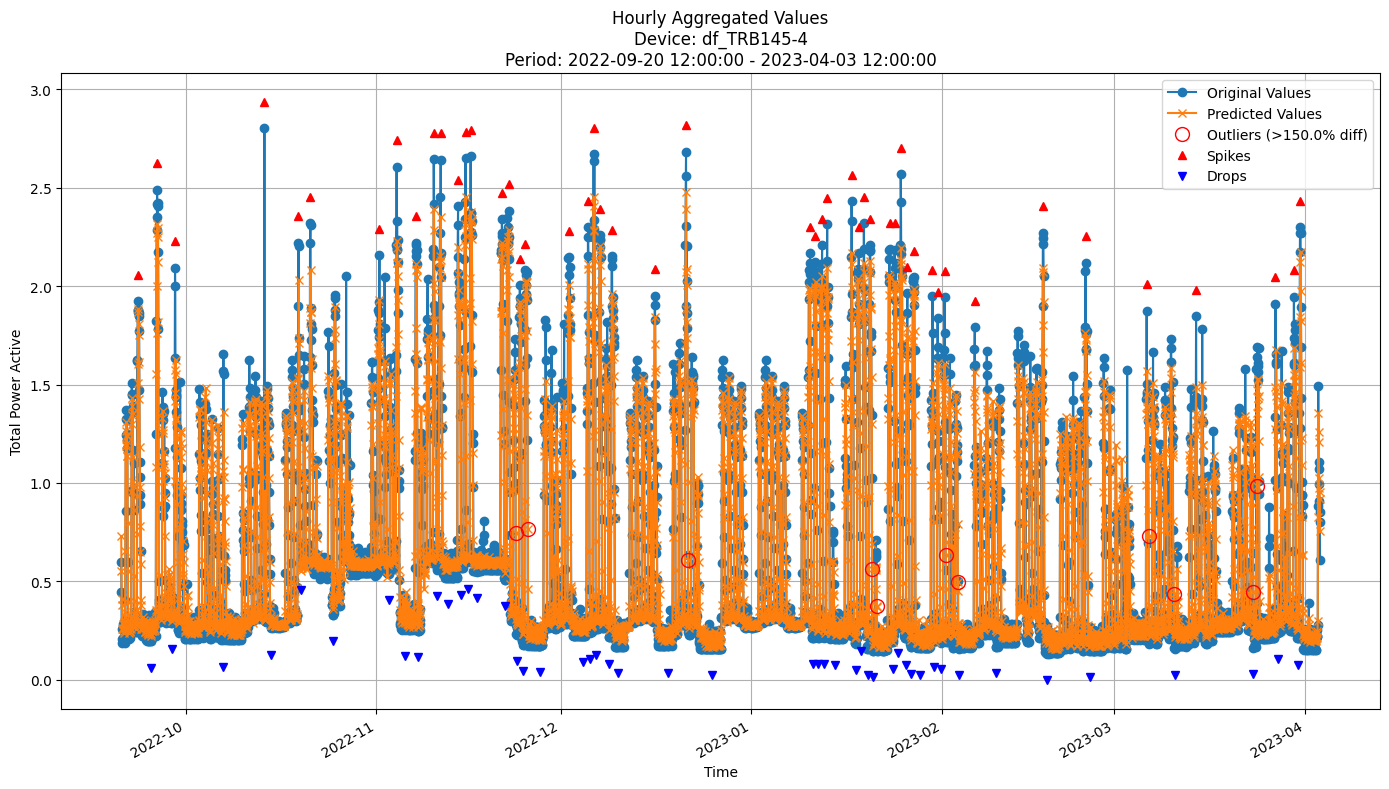


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.1286
MAE: 0.0756
MAPE: 14.6978%

Directional Metrics:
Directional Accuracy: 75.1923%
First-Diff Correlation: 0.8301

Immediate Detection (delta=0):
Spikes:
  Precision: 0.5000
  Recall: 0.3673
  F1 Score: 0.4235
Drops:
  Precision: 0.1143
  Recall: 0.0833
  F1 Score: 0.0964

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.7778
  Recall: 0.5714
  F1 Score: 0.6588
Drops:
  Precision: 0.1714
  Recall: 0.1250
  F1 Score: 0.1446


In [21]:
for device_id in rf_train_period_predictions.keys():
    y_train = rf_train_period_predictions[device_id][-1]['y_true']
    y_pred_train = rf_train_period_predictions[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last periods of predictions

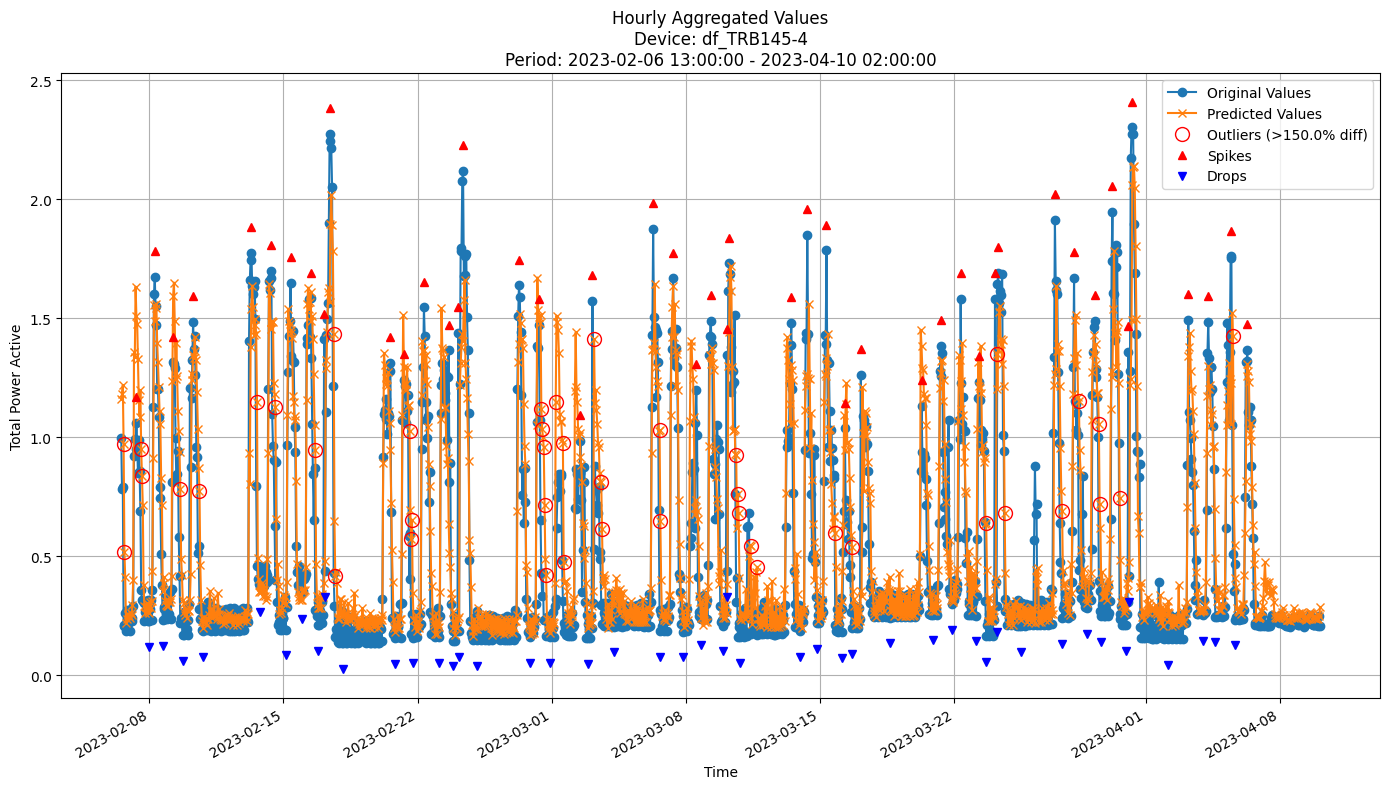


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2347
MAE: 0.1483
MAPE: 34.6715%

Directional Metrics:
Directional Accuracy: 59.0273%
First-Diff Correlation: 0.4102

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0750
  Recall: 0.0638
  F1 Score: 0.0690
Drops:
  Precision: 0.1795
  Recall: 0.1522
  F1 Score: 0.1647

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2750
  Recall: 0.2340
  F1 Score: 0.2529
Drops:
  Precision: 0.2308
  Recall: 0.1957
  F1 Score: 0.2118


In [22]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in rf_valid_period_predictions.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, rf_valid_period_predictions[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, rf_valid_period_predictions[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### Hoeffding Tree

In [ ]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

grace_period = 0
delta = 0.05
max_depth = 3
tau = 0.1
leaf_prediction="mean"

hoef = HoeffdingTreeRegressor(
        grace_period=grace_period,
        max_depth=max_depth,
        delta=delta,
        tau=tau,
        leaf_prediction=leaf_prediction
    )

# BEST RMSE: 0.258
#    Best Parameters: {'max_depth': 10, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST MAE: 0.162
#    Best Parameters: {'max_depth': 15, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST MAPE: 30.209%
#    Best Parameters: {'max_depth': 15, 'grace_period': 48, 'tau': 0.1, 'delta': 0.1}
# BEST DIR_ACCURACY: 54.170%
#    Best Parameters: {'max_depth': 5, 'grace_period': 0, 'tau': 0.1, 'delta': 0.005}
# BEST FIRST_DIFF_CORR: 41.677%
#    Best Parameters: {'max_depth': 3, 'grace_period': 0, 'tau': 0.1, 'delta': 0.05}
# BEST SPIKES_F1: 18.787%
#    Best Parameters: {'max_depth': 3, 'grace_period': 24, 'tau': 0.001, 'delta': 0.05}
# BEST DROPS_F1: 10.620%
#    Best Parameters: {'max_depth': 10, 'grace_period': 24, 'tau': 0.1, 'delta': 0.005}


In [24]:
hoef_all_train_preds, hoef_all_valid_preds, \
hoef_all_train_metrics, hoef_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=hoef, 
    train=train, 
    valid=valid, 
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3827
	MAE: 0.2828
	MAPE: 33.7098%

Directional Metrics:
	Directional Accuracy: 47.5410%
	First-Diff Correlation: 0.2701

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0500
		Recall: 0.0909
		F1: 0.0645
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.1500
		Recall: 0.2727
		F1: 0.1935
	Drops:
		Precision: 0.1905
		Recall: 0.3636
		F1: 0.2500
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.1213
	MAE: 5.1

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3845
	MAE: 0.2877
	MAPE: 52.3411%

Directional Metrics:
	Directional Accuracy: 51.1177%
	First-Diff Correlation: 0.3790

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.5702
	MAE: 4.5

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3151
	MAE: 0.2271
	MAPE: 56.5776%

Directional Metrics:
	Directional Accuracy: 52.9061%
	First-Diff Correlation: 0.3278

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0476
		Recall: 0.0526
		F1: 0.0500
	Drops:
		Precision: 0.1364
		Recall: 0.1500
		F1: 0.1429

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.2857
		Recall: 0.3158
		F1: 0.3000
	Drops:
		Precision: 0.2273
		Recall: 0.2500
		F1: 0.2381
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.2344
	MAE: 3.7

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3244
	MAE: 0.2466
	MAPE: 84.0442%

Directional Metrics:
	Directional Accuracy: 56.6879%
	First-Diff Correlation: 0.4719

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2000
		Recall: 0.2500
		F1: 0.2222
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.4000
		Recall: 0.5000
		F1: 0.4444
	Drops:
		Precision: 0.2000
		Recall: 0.3333
		F1: 0.2500
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.3071
	MAE: 4.6

#### Results

In [25]:
print("\n\nTrain period metrics:")
hoef_all_time_train_metrics = all_time_aggregation_metrics(hoef_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
hoef_all_time_valid_metrics = all_time_aggregation_metrics(hoef_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.3387 ± 0.0134
	MAE: 0.2369 ± 0.0276
	MAPE: 46.7455% ± 5.3049%

	Directional Metrics:
		Directional Accuracy: 14.8889% ± 0.4437%
		First-Diff Correlation: 0.3587 ± 0.0550

	Immediate Detection (delta=0):
		Spike Precision: 0.0195 ± 0.0153
		Spike Recall: 0.1309 ± 0.1589
		Spike F1: 0.0290 ± 0.0210
		Drop Precision: 0.0201 ± 0.0279
		Drop Recall: 0.0611 ± 0.0620
		Drop F1: 0.0292 ± 0.0374

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0986 ± 0.1096
		Spike Recall: 0.3460 ± 0.2200
		Spike F1: 0.1371 ± 0.1307
		Drop Precision: 0.0396 ± 0.0381
		Drop Recall: 0.2825 ± 0.3122
		Drop F1: 0.0606 ± 0.0534
Daily Metrics:
	RMSE: 4.8146 ± 0.6125
	MAE: 4.0155 ± 0.5852
	MAPE: 32.2443% ± 3.3714%

	Directional Metrics:
		Directional Accuracy: 63.8499% ± 9.0206%
		First-Diff Correlation: 0.8432 ± 0.0203

	Immediate Detection (delta=0):

#### Training plots
Plot only the last period of predictions

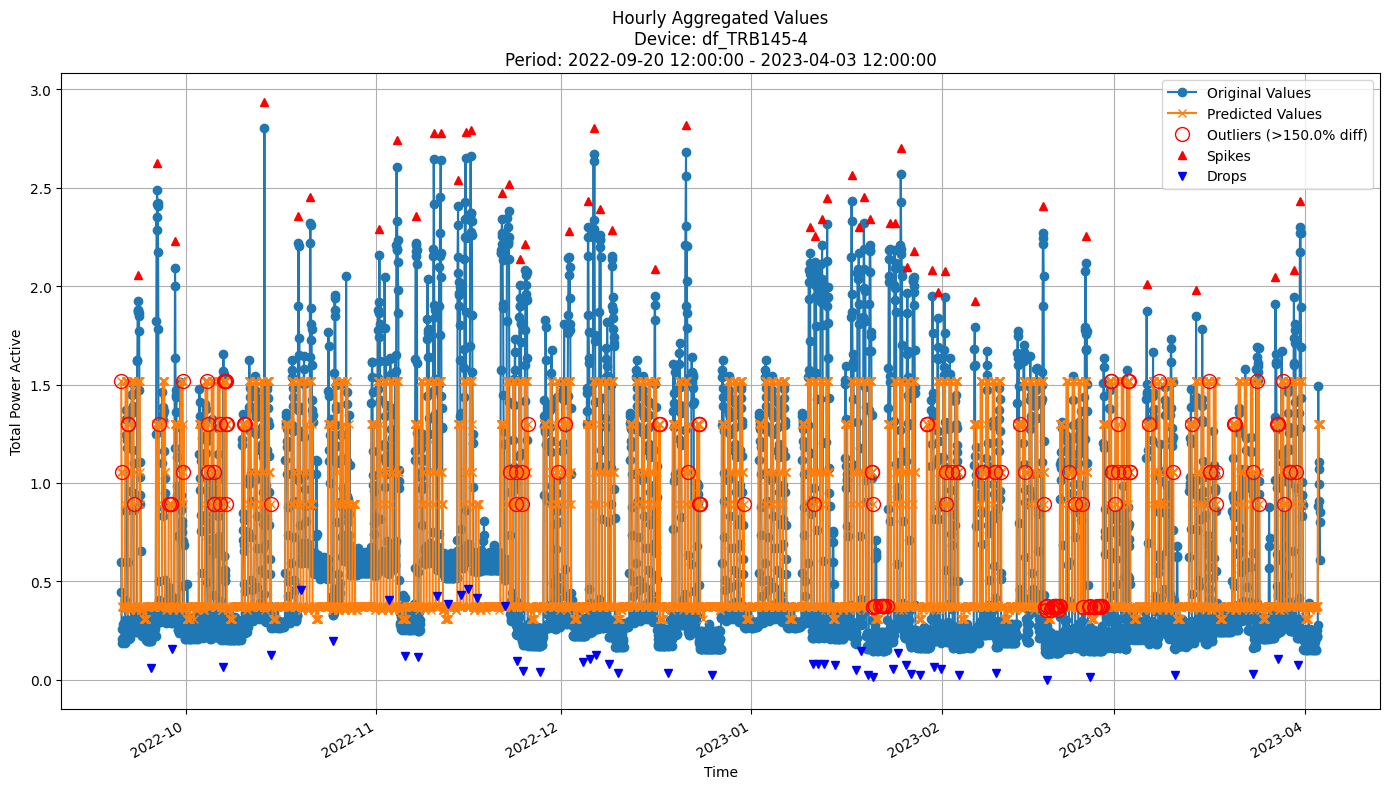


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3301
MAE: 0.2340
MAPE: 49.5146%

Directional Metrics:
Directional Accuracy: 14.8504%
First-Diff Correlation: 0.4062

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0347
  Recall: 0.1224
  F1 Score: 0.0541
Drops:
  Precision: 0.0260
  Recall: 0.1042
  F1 Score: 0.0417

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.1329
  Recall: 0.4694
  F1 Score: 0.2072
Drops:
  Precision: 0.0625
  Recall: 0.2500
  F1 Score: 0.1000


In [26]:
for device_id in hoef_all_train_preds.keys():
    y_train = hoef_all_train_preds[device_id][-1]['y_true']
    y_pred_train = hoef_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

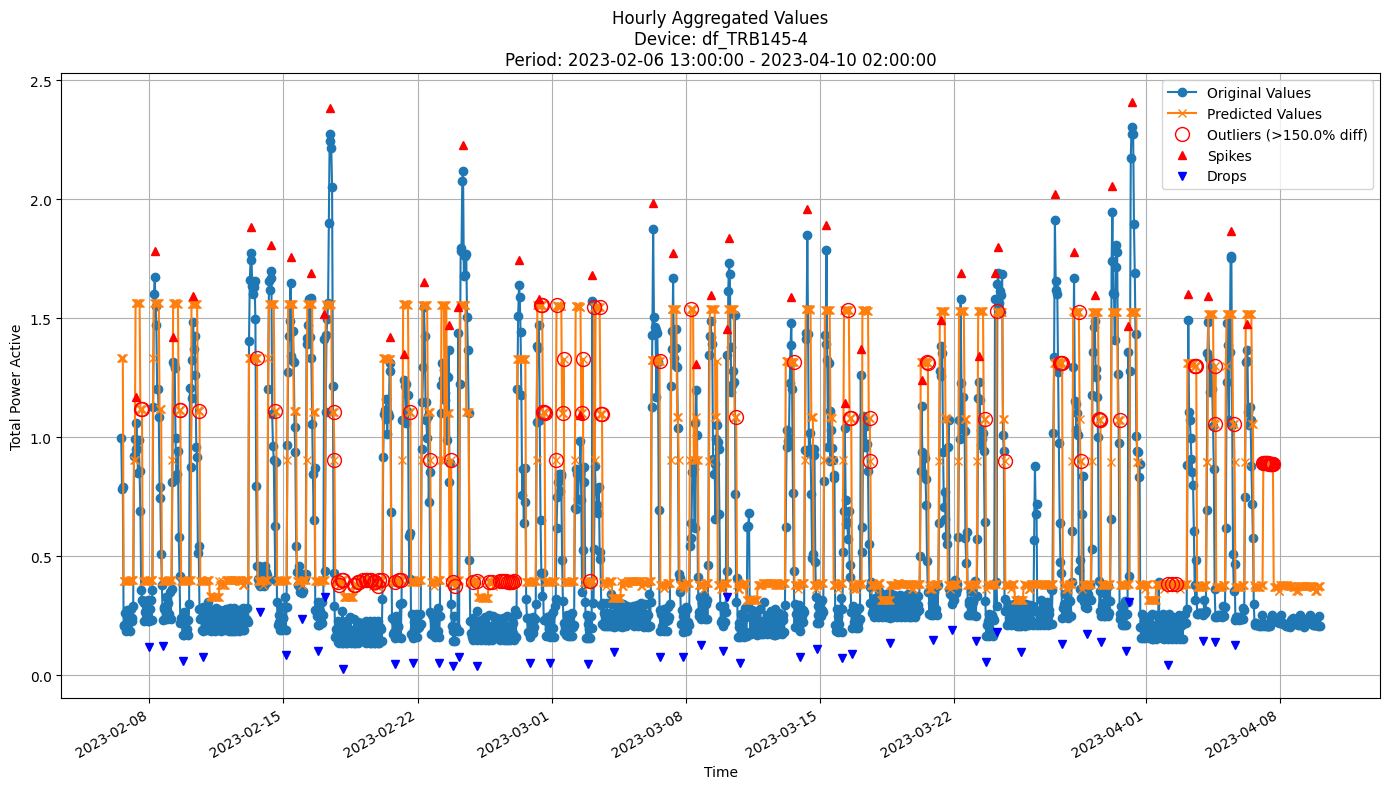


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3224
MAE: 0.2397
MAPE: 67.7105%

Directional Metrics:
Directional Accuracy: 53.2312%
First-Diff Correlation: 0.3977

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0577
  Recall: 0.0638
  F1 Score: 0.0606
Drops:
  Precision: 0.1154
  Recall: 0.1304
  F1 Score: 0.1224

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.2885
  Recall: 0.3191
  F1 Score: 0.3030
Drops:
  Precision: 0.2115
  Recall: 0.2391
  F1 Score: 0.2245


In [27]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in hoef_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, hoef_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, hoef_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (Hoeffding Tree)

In [28]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 10
max_features = 0.8
grace_period = 10
split_confidence = 0.5
depth = 10
tau = 0.01

arf_hf = ARFRegressor(
        n_models=n_models,
        max_features=max_features,
        aggregation_method='median',
        grace_period=grace_period,
        max_depth=depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
    )

In [29]:
arf_hf_all_train_preds, arf_hf_all_valid_preds, \
arf_hf_all_train_metrics, arf_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=arf_hf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3631
	MAE: 0.2355
	MAPE: 27.3743%

Directional Metrics:
	Directional Accuracy: 52.1610%
	First-Diff Correlation: 0.3317

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 5.4454
	MAE: 4.2

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3245
	MAE: 0.2214
	MAPE: 39.9123%

Directional Metrics:
	Directional Accuracy: 57.9732%
	First-Diff Correlation: 0.4104

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.9443
	MAE: 3.1

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2498
	MAE: 0.1676
	MAPE: 37.3576%

Directional Metrics:
	Directional Accuracy: 51.8629%
	First-Diff Correlation: 0.3531

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.1053
		Recall: 0.1000
		F1: 0.1026

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3158
		Recall: 0.3158
		F1: 0.3158
	Drops:
		Precision: 0.1579
		Recall: 0.1500
		F1: 0.1538
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.3846
	MAE: 1.9

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.1904
	MAE: 0.1279
	MAPE: 40.8609%

Directional Metrics:
	Directional Accuracy: 59.2357%
	First-Diff Correlation: 0.4171

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.3333
		Recall: 0.2500
		F1: 0.2857
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.2832
	MAE: 1.8

#### Results

In [30]:
print("\n\nTrain period metrics:")
arf_hf_all_time_train_metrics = all_time_aggregation_metrics(arf_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_hf_all_time_valid_metrics = all_time_aggregation_metrics(arf_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.2586 ± 0.0565
	MAE: 0.1637 ± 0.0445
	MAPE: 31.6056% ± 11.1158%

	Directional Metrics:
		Directional Accuracy: 58.5306% ± 7.2030%
		First-Diff Correlation: 0.4946 ± 0.1244

	Immediate Detection (delta=0):
		Spike Precision: 0.1061 ± 0.1370
		Spike Recall: 0.0573 ± 0.0757
		Spike F1: 0.0737 ± 0.0958
		Drop Precision: 0.0501 ± 0.0579
		Drop Recall: 0.0278 ± 0.0332
		Drop F1: 0.0353 ± 0.0413

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.1996 ± 0.2542
		Spike Recall: 0.1079 ± 0.1412
		Spike F1: 0.1387 ± 0.1784
		Drop Precision: 0.0631 ± 0.0757
		Drop Recall: 0.0347 ± 0.0422
		Drop F1: 0.0443 ± 0.0529
Daily Metrics:
	RMSE: 3.1903 ± 0.9528
	MAE: 2.4899 ± 0.8054
	MAPE: 20.5581% ± 9.5556%

	Directional Metrics:
		Directional Accuracy: 76.8486% ± 5.8319%
		First-Diff Correlation: 0.8792 ± 0.1838

	Immediate Detection (delta=0)

#### Training plots

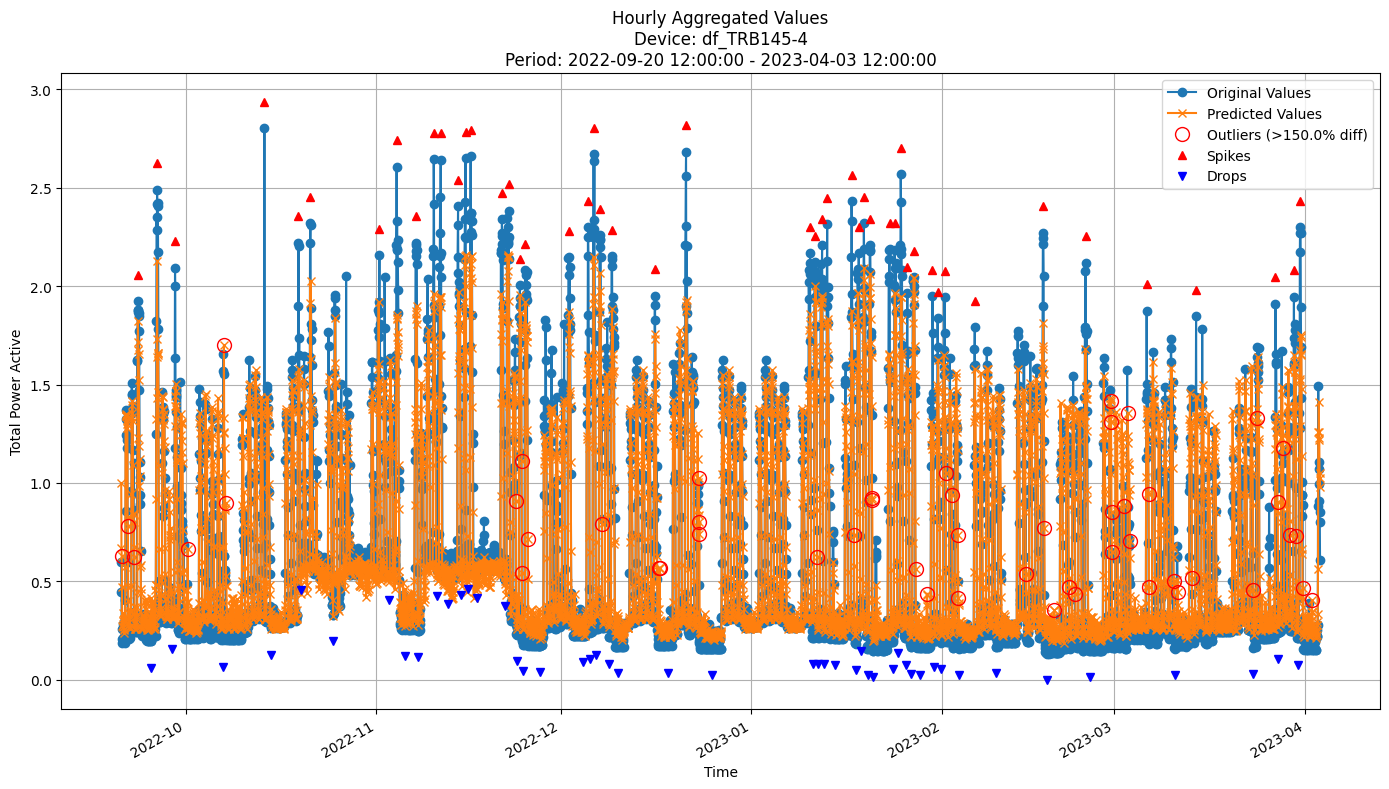


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2175
MAE: 0.1308
MAPE: 25.1906%

Directional Metrics:
Directional Accuracy: 62.5641%
First-Diff Correlation: 0.5781

Immediate Detection (delta=0):
Spikes:
  Precision: 0.2647
  Recall: 0.1837
  F1 Score: 0.2169
Drops:
  Precision: 0.1143
  Recall: 0.0833
  F1 Score: 0.0964

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.5000
  Recall: 0.3469
  F1 Score: 0.4096
Drops:
  Precision: 0.1429
  Recall: 0.1042
  F1 Score: 0.1205


In [31]:
for device_id in arf_hf_all_train_preds.keys():
    y_train = arf_hf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_hf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

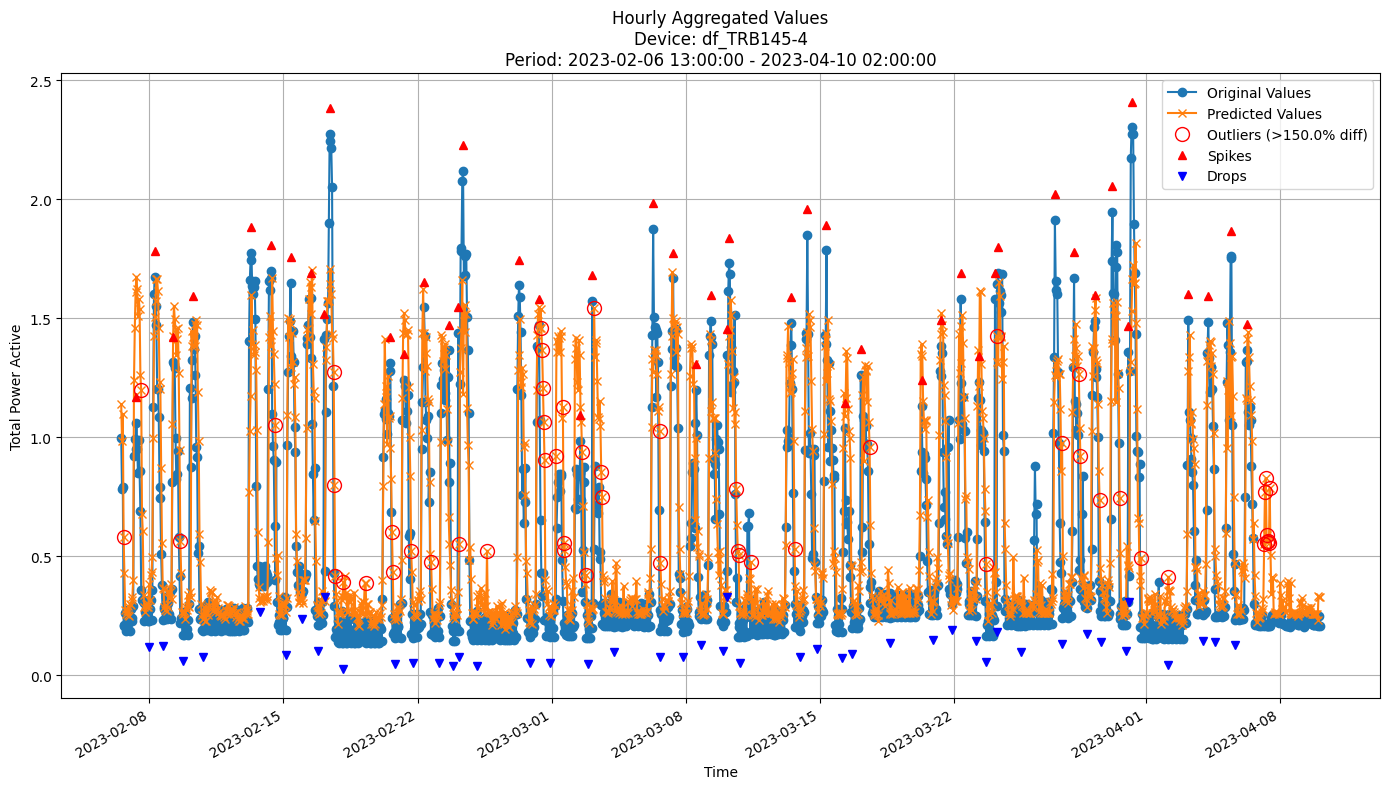


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2560
MAE: 0.1695
MAPE: 41.2028%

Directional Metrics:
Directional Accuracy: 58.0280%
First-Diff Correlation: 0.4114

Immediate Detection (delta=0):
Spikes:
  Precision: 0.1163
  Recall: 0.1064
  F1 Score: 0.1111
Drops:
  Precision: 0.0930
  Recall: 0.0870
  F1 Score: 0.0899

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.4186
  Recall: 0.3830
  F1 Score: 0.4000
Drops:
  Precision: 0.1395
  Recall: 0.1304
  F1 Score: 0.1348


In [32]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_hf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### FastODT

In [33]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario
grace_period = 10
split_confidence = 0.005
depth = 50
eagerness = 1000
grace_period_depth = 0 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes
option = 'hf'

fodt = fastodt.FastODT(
        depth=depth,
        grace_period=grace_period,
        split_confidence=split_confidence,
        option=option,
        eagerness = eagerness,
        grace_period_depth = grace_period_depth
    )

# BEST RMSE: 0.332
#    Best Parameters: {'depth': 50, 'grace_period': 10, 'grace_period_depth': -1, 'eagerness': 0, 'split_confidence': 0.1, 'option': 'hf'}
# BEST MAE: 0.247
#    Best Parameters: {'depth': 70, 'grace_period': 10, 'grace_period_depth': 0, 'eagerness': 200, 'split_confidence': 0.05, 'option': 'hf'}
# BEST MAPE: 42.162%
#    Best Parameters: {'depth': 5, 'grace_period': 0, 'grace_period_depth': -1, 'eagerness': 100, 'split_confidence': 0.005, 'option': 'hf'}
# BEST DIR_ACCURACY: 60.316%
#    Best Parameters: {'depth': 50, 'grace_period': 10, 'grace_period_depth': 0, 'eagerness': 1000, 'split_confidence': 0.005, 'option': 'hf'}
# BEST FIRST_DIFF_CORR: 49.973%
#    Best Parameters: {'depth': 50, 'grace_period': 10, 'grace_period_depth': 0, 'eagerness': 1000, 'split_confidence': 0.005, 'option': 'hf'}
# BEST SPIKES_F1: 23.121%
#    Best Parameters: {'depth': 50, 'grace_period': 24, 'grace_period_depth': 1, 'eagerness': 0, 'split_confidence': 0.001, 'option': 'hf'}
# BEST DROPS_F1: 9.139%
#    Best Parameters: {'depth': 30, 'grace_period': 35, 'grace_period_depth': 1, 'eagerness': 0, 'split_confidence': 0.001, 'option': 'hf'}

In [34]:
fodt_all_train_preds, fodt_all_valid_preds, \
fodt_all_train_metrics, fodt_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=fodt, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5343
	MAE: 0.3787
	MAPE: 39.5036%

Directional Metrics:
	Directional Accuracy: 54.3964%
	First-Diff Correlation: 0.3843

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 9.6804
	MAE: 8.0

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5615
	MAE: 0.3913
	MAPE: 55.4601%

Directional Metrics:
	Directional Accuracy: 58.7183%
	First-Diff Correlation: 0.4822

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 9.1108
	MAE: 7.5

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2853
	MAE: 0.2128
	MAPE: 55.6827%

Directional Metrics:
	Directional Accuracy: 58.5693%
	First-Diff Correlation: 0.4751

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 3.5239
	MAE: 2.8

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2964
	MAE: 0.2315
	MAPE: 83.2707%

Directional Metrics:
	Directional Accuracy: 60.5096%
	First-Diff Correlation: 0.4475

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.3933
	MAE: 3.2

#### Results

In [35]:
print("\n\nTrain period metrics:")
fodt_all_time_train_metrics = all_time_aggregation_metrics(fodt_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
fodt_all_time_valid_metrics = all_time_aggregation_metrics(fodt_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4060 ± 0.0254
	MAE: 0.2788 ± 0.0176
	MAPE: 49.5389% ± 3.1126%

	Directional Metrics:
		Directional Accuracy: 62.6856% ± 9.0981%
		First-Diff Correlation: 0.5201 ± 0.1134

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 6.4790 ± 0.6781
	MAE: 5.2992 ± 0.5283
	MAPE: 40.1964% ± 1.8628%

	Directional Metrics:
		Directional Accuracy: 73.6043% ± 2.1798%
		First-Diff Correlation: 0.7680 ± 0.1626

	Immediate Detection (delta=0):

#### Training plots


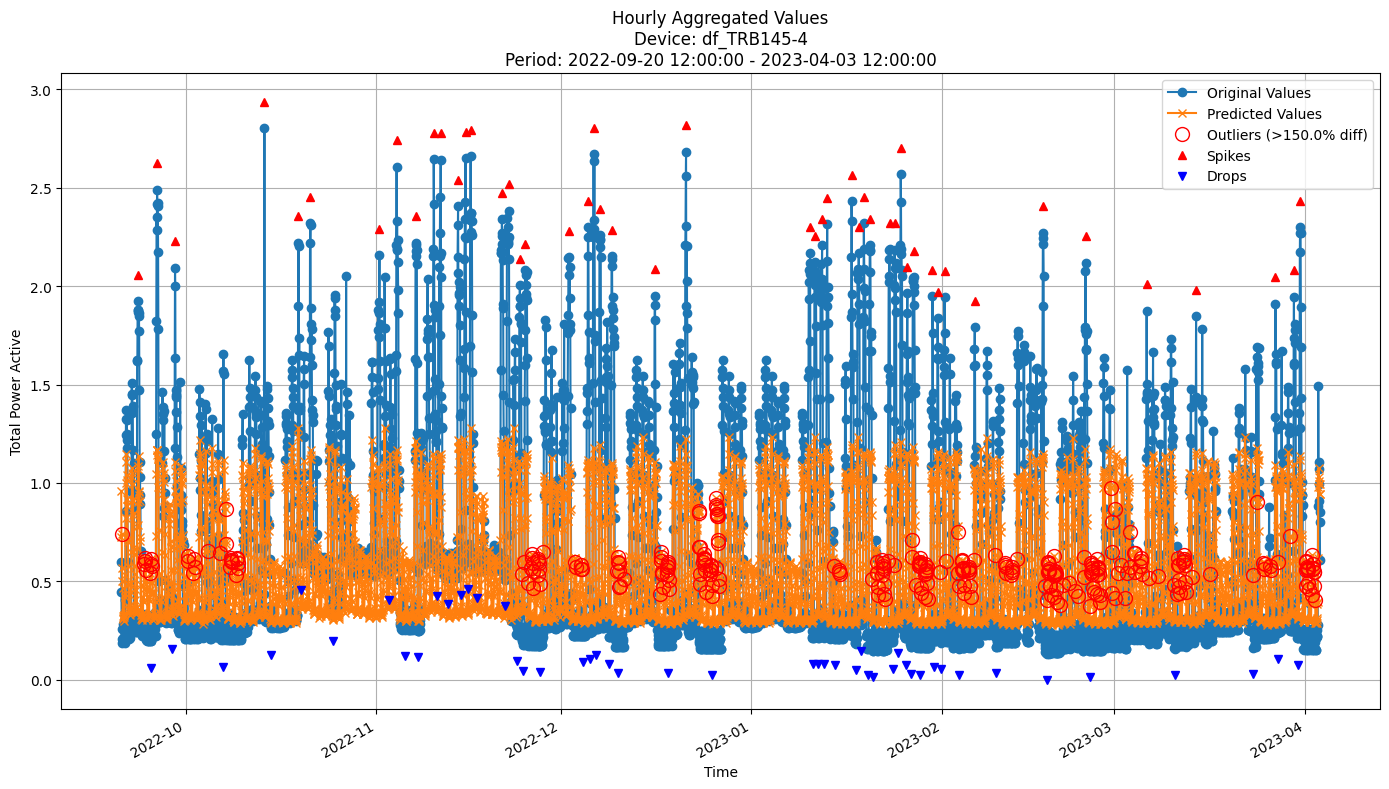


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3671
MAE: 0.2555
MAPE: 51.7997%

Directional Metrics:
Directional Accuracy: 68.4615%
First-Diff Correlation: 0.6268

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [36]:
for device_id in fodt_all_train_preds.keys():
    y_train = fodt_all_train_preds[device_id][-1]['y_true']
    y_pred_train = fodt_all_train_preds[device_id][-1]['y_pred']
    
    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

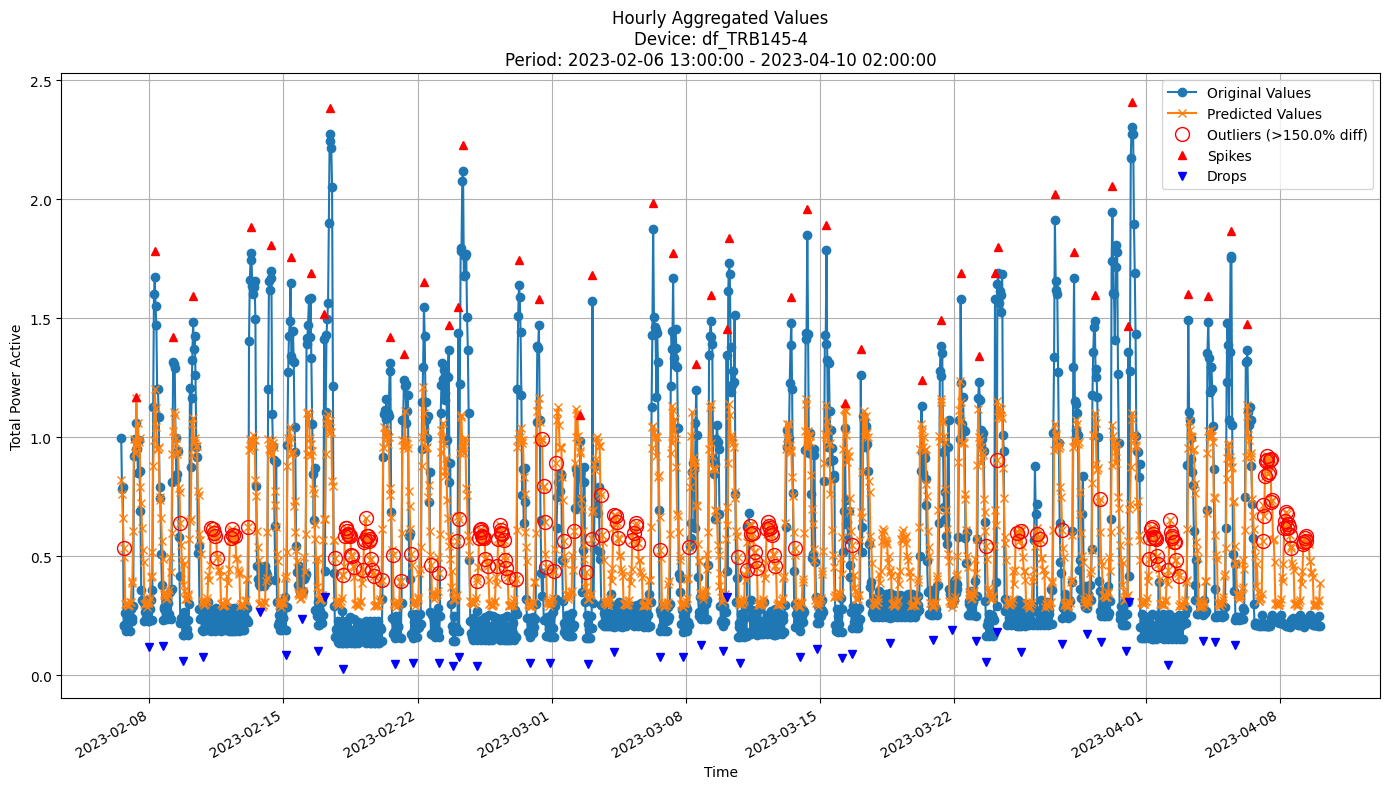


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.2968
MAE: 0.2264
MAPE: 66.4198%

Directional Metrics:
Directional Accuracy: 58.0280%
First-Diff Correlation: 0.4865

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [37]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in fodt_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, fodt_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, fodt_all_valid_preds[device_id][i]['y_pred']], axis=0)
    
    plot_hourly_predictions(y_valid, 
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY, 
                            device_id=device_id, 
                            outlier_threshold=1.5)

### ARF (FastODT)

In [38]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario

n_models = 20
grace_period = 0  # by default works for all leaves
aggregation_method = "mean"
split_confidence = 0.005
tau = 0.01
max_depth = 100
eagerness = 200

arf = ARFRegressorFODT(
        n_models=n_models,
        aggregation_method=aggregation_method,
        grace_period=grace_period,
        max_depth=max_depth,
        delta=split_confidence,
        tau=tau,
        seed=42,
        max_feature=0.7,
        eagerness=eagerness,
    )


In [39]:
arf_all_train_preds, arf_all_valid_preds, \
arf_all_train_metrics, arf_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=arf,
    train=train,
    valid=valid,
    incremental=True,
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq,
    start_split=0,
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5095
	MAE: 0.3385
	MAPE: 37.6630%

Directional Metrics:
	Directional Accuracy: 55.5887%
	First-Diff Correlation: 0.2616

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.2500
		Recall: 0.0909
		F1: 0.1333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.5000
		Recall: 0.1818
		F1: 0.2667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.6896
	MAE: 6.4

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.5509
	MAE: 0.4278
	MAPE: 85.0649%

Directional Metrics:
	Directional Accuracy: 58.4203%
	First-Diff Correlation: 0.4526

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 7.5391
	MAE: 6.1

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3104
	MAE: 0.2514
	MAPE: 73.0804%

Directional Metrics:
	Directional Accuracy: 56.6319%
	First-Diff Correlation: 0.4170

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.1623
	MAE: 3.2

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2431
	MAE: 0.2007
	MAPE: 63.7054%

Directional Metrics:
	Directional Accuracy: 59.2357%
	First-Diff Correlation: 0.5633

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.5000
		Recall: 0.2500
		F1: 0.3333
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 0.5000
		F1: 0.6667
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.8871
	MAE: 2.3

#### Results

In [40]:
print("\n\nTrain period metrics:")
arf_all_time_train_metrics = all_time_aggregation_metrics(arf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\Valid period metrics:")
arf_all_time_valid_metrics = all_time_aggregation_metrics(arf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)



Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.4010 ± 0.0369
	MAE: 0.2982 ± 0.0414
	MAPE: 65.4452% ± 12.8136%

	Directional Metrics:
		Directional Accuracy: 61.4919% ± 1.1392%
		First-Diff Correlation: 0.4254 ± 0.0672

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 6.0603 ± 0.6899
	MAE: 4.9130 ± 0.6317
	MAPE: 45.2847% ± 6.8780%

	Directional Metrics:
		Directional Accuracy: 70.7286% ± 6.1593%
		First-Diff Correlation: 0.7812 ± 0.1097

	Immediate Detection (delta=0)

#### Training plots


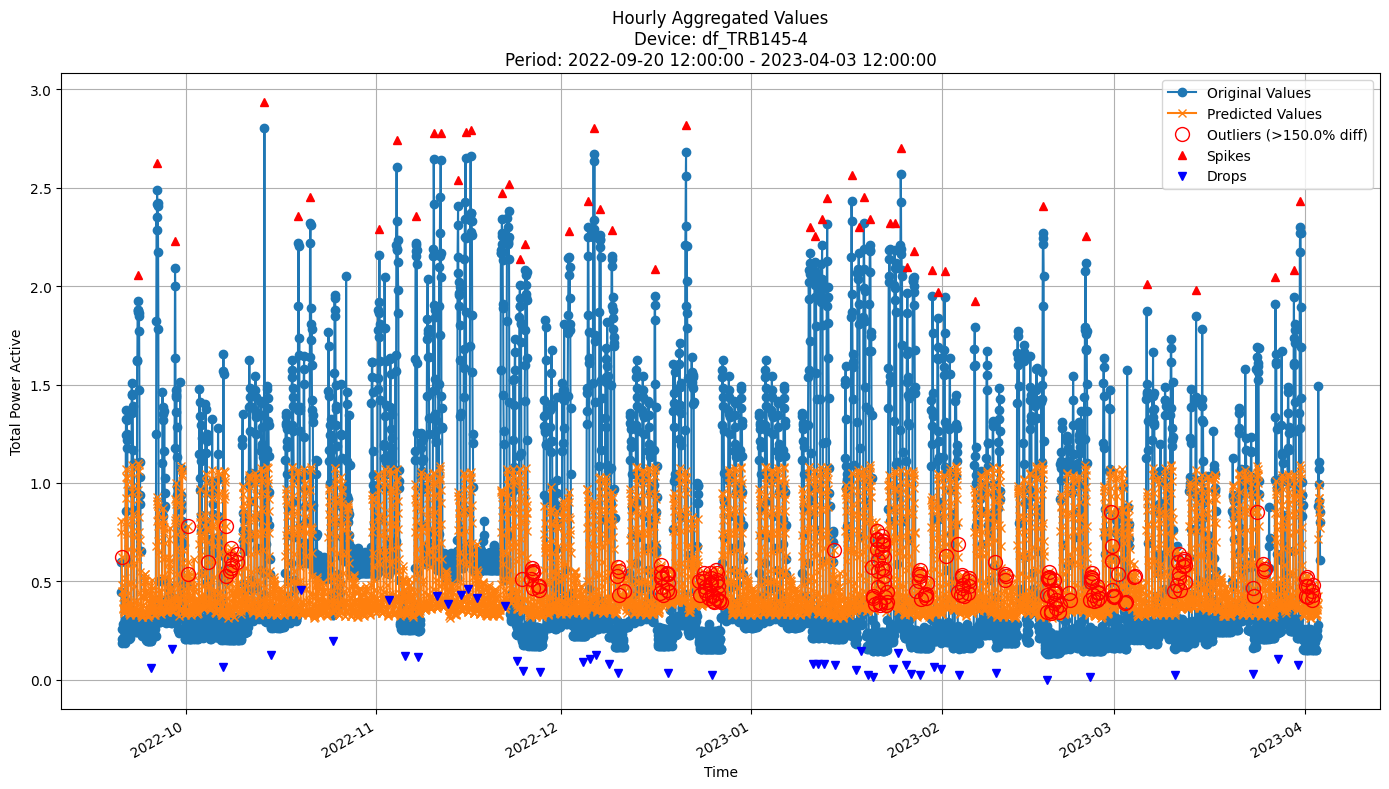


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.4215
MAE: 0.2889
MAPE: 53.0738%

Directional Metrics:
Directional Accuracy: 62.3504%
First-Diff Correlation: 0.4602

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [41]:
for device_id in arf_all_train_preds.keys():
    y_train = arf_all_train_preds[device_id][-1]['y_true']
    y_pred_train = arf_all_train_preds[device_id][-1]['y_pred']

    # Plot hourly predictions
    plot_hourly_predictions(y_train,
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

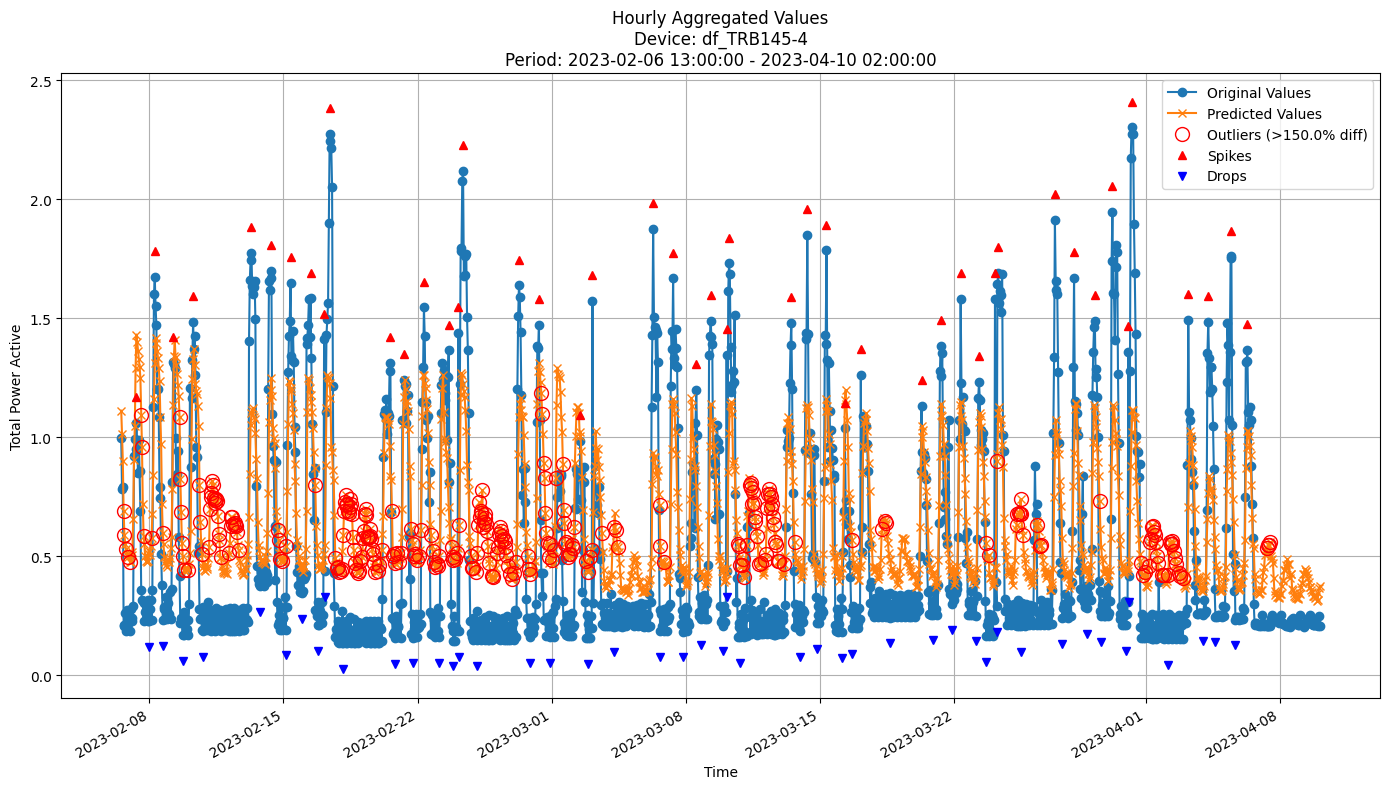


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3231
MAE: 0.2698
MAPE: 87.0857%

Directional Metrics:
Directional Accuracy: 57.2951%
First-Diff Correlation: 0.4170

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [42]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in arf_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, arf_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, arf_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost

In [43]:
update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:

learning_rate = 1.0
length = 50
incubation_mode = "DEFAULT"
depth = 50
grace_period = 10
split_confidence_hf = 0.005
max_feature = 1.0
eagerness = 1000
grace_period_depth = 0 # set to 1 to use only for first node, set to -1 to use for all nodes, set to N to use for N nodes

incb = IncubationBoost(
    fastodt.FastODT,
    length=length,
    learning_rate=learning_rate,
    incubationMode=incubation_mode,
    baseLearnerOptions=(depth, grace_period, split_confidence, "hf", max_features, eagerness, grace_period_depth),
    verbose=False
    )

# BEST RMSE: 0.357
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 70, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST MAE: 0.276
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 70, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST MAPE: 61.889%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (70, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST DIR_ACCURACY: 60.316%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (50, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST FIRST_DIFF_CORR: 49.973%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (50, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST SPIKES_F1: 6.190%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}
# BEST DROPS_F1: 0.000%
#    Best Parameters: {'baseLearner': <class 'src.trees.fastodt.FastODT'>, 'length': 50, 'learning_rate': 1.0, 'incubationMode': 'DEFAULT', 'baseLearnerOptions': (15, 10, 0.005, 'hf', 1.0, 1000, 0), 'verbose': False}

In [44]:
incb_all_train_preds, incb_all_valid_preds, \
incb_all_train_metrics, incb_all_valid_metrics = all_valid_splits_seq_fit_predict(
    model=incb, 
    train=train, 
    valid=valid, 
    incremental=True, 
    data_freq=DATA_FREQUENCY,
    update_freq=update_freq, 
    start_split=0, 
    #end_split=4,  # Use only the third and fourth splits
    verbose=True
)

Processing splits:   0%|          | 0/7 [00:00<?, ?it/s]

Processing devices in split 0:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-10-17 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-10-17 13:00:00 - 2022-11-14 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7175
	MAE: 0.5626
	MAPE: 60.7742%

Directional Metrics:
	Directional Accuracy: 48.8823%
	First-Diff Correlation: 0.3190

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 14.4137
	MAE: 12

Processing devices in split 1:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2022-11-14 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2022-11-14 13:00:00 - 2022-12-12 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.7368
	MAE: 0.5040
	MAPE: 52.5707%

Directional Metrics:
	Directional Accuracy: 48.4352%
	First-Diff Correlation: 0.3734

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 13.6129
	MAE: 11

Processing devices in split 2:   0%|          | 0/1 [00:00<?, ?it/s]

... (5 outputs left out)

Processing devices in split 5:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-03-06 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-03-06 13:00:00 - 2023-04-03 12:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3823
	MAE: 0.2373
	MAPE: 35.8245%

Directional Metrics:
	Directional Accuracy: 51.4158%
	First-Diff Correlation: 0.3636

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.1413
	MAE: 4.9

Processing devices in split 6:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-03 12:00:00
Train predictions completed.
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2917
	MAE: 0.1714
	MAPE: 34.8660%

Directional Metrics:
	Directional Accuracy: 50.9554%
	First-Diff Correlation: 0.4131

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.1253
	MAE: 2.8

#### Results

In [45]:
print("\n\nTrain period metrics:")
incb_all_time_train_metrics = all_time_aggregation_metrics(incb_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
print("\n\nValid period metrics:")
incb_all_time_valid_metrics = all_time_aggregation_metrics(incb_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)




Train period metrics:


Aggregated Metrics Across Periods
Device ID: df_TRB145-4
--------------------------------------------------
Hourly Metrics:
	RMSE: 0.5593 ± 0.0404
	MAE: 0.3773 ± 0.0381
	MAPE: 46.3442% ± 2.0274%

	Directional Metrics:
		Directional Accuracy: 53.8791% ± 5.2676%
		First-Diff Correlation: 0.4338 ± 0.1132

	Immediate Detection (delta=0):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000

	1-Hour Delayed Detection (delta=1):
		Spike Precision: 0.0000 ± 0.0000
		Spike Recall: 0.0000 ± 0.0000
		Spike F1: 0.0000 ± 0.0000
		Drop Precision: 0.0000 ± 0.0000
		Drop Recall: 0.0000 ± 0.0000
		Drop F1: 0.0000 ± 0.0000
Daily Metrics:
	RMSE: 10.5624 ± 1.0982
	MAE: 8.6023 ± 1.0684
	MAPE: 44.8758% ± 2.8226%

	Directional Metrics:
		Directional Accuracy: 77.3258% ± 2.7970%
		First-Diff Correlation: 0.8240 ± 0.1632

	Immediate Detection (delta=0)

#### Train plots

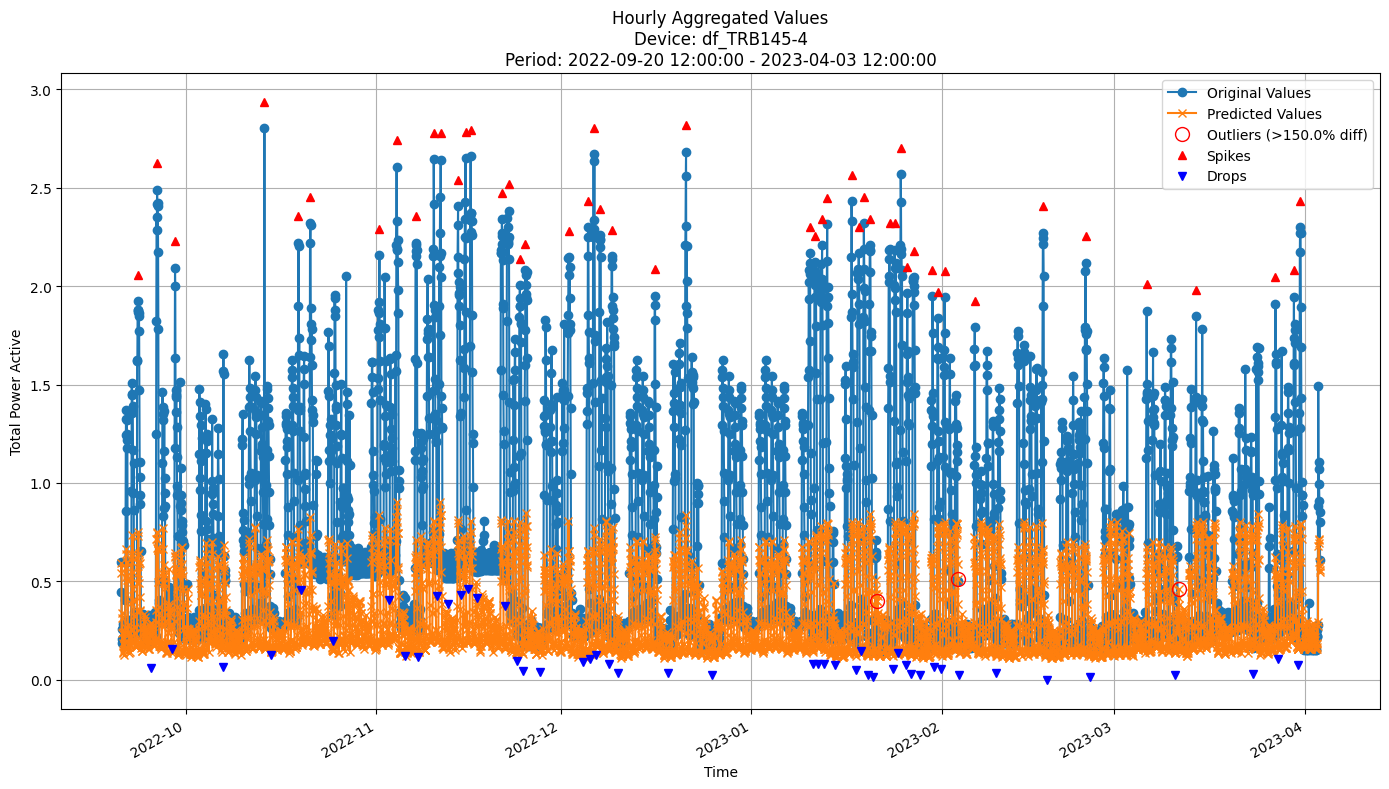


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.5232
MAE: 0.3433
MAPE: 42.9005%

Directional Metrics:
Directional Accuracy: 58.6538%
First-Diff Correlation: 0.5409

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [46]:
for device_id in incb_all_train_preds.keys():
    y_train = incb_all_train_preds[device_id][-1]['y_true']
    y_pred_train = incb_all_train_preds[device_id][-1]['y_pred']
    plot_hourly_predictions(y_train, 
                            y_pred_train, 
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id, 
                            outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

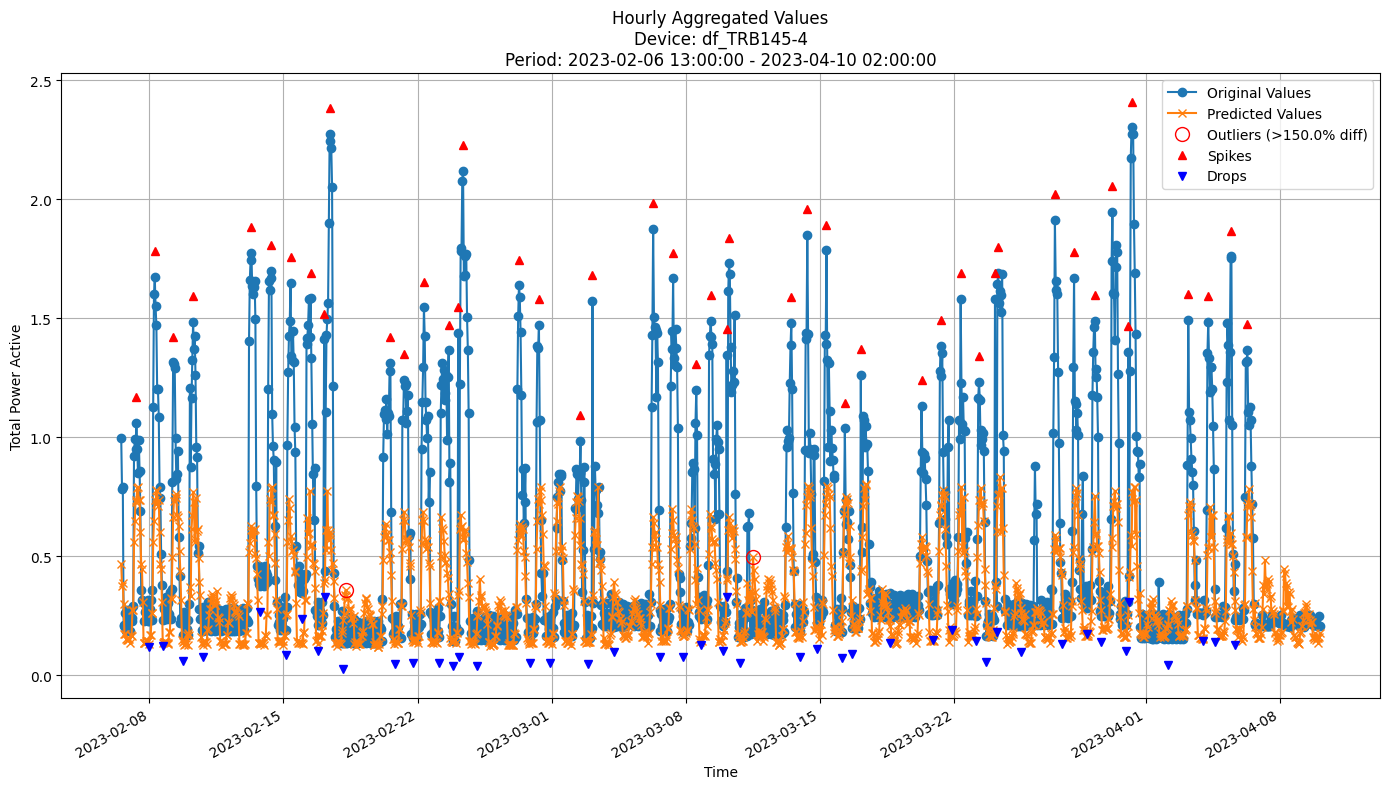


Performance Metrics for Hourly Aggregated Data
Basic Prediction Metrics:
RMSE: 0.3823
MAE: 0.2332
MAPE: 37.1015%

Directional Metrics:
Directional Accuracy: 51.0993%
First-Diff Correlation: 0.3974

Immediate Detection (delta=0):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000

1-Hour Delayed Detection (delta=1):
Spikes:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000
Drops:
  Precision: 0.0000
  Recall: 0.0000
  F1 Score: 0.0000


In [47]:
join_periods = [-3, -2, -1]
# Device iteration
for device_id in incb_all_valid_preds.keys():
    y_valid = pd.Series([])
    y_pred_valid = pd.Series([])
    # Concatenate predictions for the specified periods
    for i in join_periods:
        y_valid = pd.concat([y_valid, incb_all_valid_preds[device_id][i]['y_true']], axis=0)
        y_pred_valid = pd.concat([y_pred_valid, incb_all_valid_preds[device_id][i]['y_pred']], axis=0)

    plot_hourly_predictions(y_valid,
                            y_pred_valid,
                            data_freq=DATA_FREQUENCY,
                            device_id=device_id,
                            outlier_threshold=1.5)

### iNcubation Boost (Hoeffding Tree)

In [48]:
# update_freq = "1h"  # for incremental models put the same as the data frequency to recreate real world scenario:
# n_trees = 20
# learning_rate = 0.1
# grace_period = 10
# delta = 0.5
# max_depth = 10
# tau = 0.05
# leaf_prediction = "mean"

# incb_hf = IncubationBoost(
#     HoeffdingTreeRegressor,
#     length=n_trees,
#     learning_rate=learning_rate,
#     incubationMode = "DEFAULT",
#     baseLearnerOptions = (grace_period, max_depth, delta, tau, leaf_prediction),
#     verbose=False
#     )


In [49]:
# incb_hf_all_train_preds, incb_hf_all_valid_preds, \
# incb_hf_all_train_metrics, incb_hf_all_valid_metrics = all_valid_splits_seq_fit_predict(
#     model=incb_hf, 
#     train=train, 
#     valid=valid, 
#     incremental=True, 
#     data_freq=DATA_FREQUENCY,
#     update_freq=update_freq, 
#     start_split=0, 
#     #end_split=4,  # Use only the third and fourth splits
#     verbose=True
# )

#### Results

In [50]:
# print("\n\nTrain period metrics:")
# incb_hf_all_time_train_metrics = all_time_aggregation_metrics(incb_hf_all_train_metrics, data_freq=DATA_FREQUENCY, verbose=True)
# print("\n\nValid period metrics:")
# incb_hf_all_time_valid_metrics = all_time_aggregation_metrics(incb_hf_all_valid_metrics, data_freq=DATA_FREQUENCY, verbose=True)


#### Train plots

In [51]:
# for device_id in incb_hf_all_train_preds.keys():
#     y_train = incb_hf_all_train_preds[device_id][-1]['y_true']
#     y_pred_train = incb_hf_all_train_preds[device_id][-1]['y_pred']
#     plot_hourly_predictions(y_train, 
#                             y_pred_train, 
#                             data_freq=DATA_FREQUENCY,
#                             device_id=device_id, 
#                             outlier_threshold=1.5)

#### Validation plots
Plot only the last period of predictions

In [52]:
# join_periods = [-3, -2, -1]
# # Device iteration
# for device_id in incb_hf_all_valid_preds.keys():
#     y_valid = pd.Series([])
#     y_pred_valid = pd.Series([])
#     # Concatenate predictions for the specified periods
#     for i in join_periods:
#         y_valid = pd.concat([y_valid, incb_hf_all_valid_preds[device_id][i]['y_true']], axis=0)
#         y_pred_valid = pd.concat([y_pred_valid, incb_hf_all_valid_preds[device_id][i]['y_pred']], axis=0)

#     plot_hourly_predictions(y_valid,
#                             y_pred_valid,
#                             data_freq=DATA_FREQUENCY,
#                             device_id=device_id,
#                             outlier_threshold=1.5)

# Test-set Model Evaluation
(`train[-1]` + `valid[-1]`) vs `test`

In [53]:
last_valid_dates = valid[-1][0][valid[-1][0][:, 1] == "df_TRB145-4"][:, 0]
test_dates = test[0][test[0][:, 1] == "df_TRB145-4"][:, 0]
print(f"Last validation set range: {last_valid_dates[0]} - {last_valid_dates[-1]}")
print(f"Test range: {test_dates[0]} - {test_dates[-1]}")
print(f"Test set length: {len(test_dates)}")

Last validation set range: 2023-04-03 13:00:00 - 2023-04-10 02:00:00
Test range: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
Test set length: 1215


In [54]:
# Initialize the models beforehand to run this cell
models = [baseline, gbdt, rf, hoef, arf_hf, fodt, arf, incb]
model_test_results = {}
for model in models:
    if model in [gbdt, rf]:
        # Batch learning models
        incremental = False
        update_freq = "14D"
        print(f"Model: {model.__class__.__name__} - update_freq: {update_freq}")
    else:
        # Incremental learning models
        incremental = True
        update_freq = "1h"
        print(f"Model: {model.__class__.__name__} - update_freq: {update_freq}")

    _, test_preds, \
    _, test_metrics = test_set_seq_fit_predict(
        model=model, 
        train=train, 
        valid=valid,
        test=test,
        incremental=incremental, 
        data_freq=DATA_FREQUENCY,
        update_freq=update_freq,
        spike_prominence=10,
        normalize_robust=True,
        predict_train=False,
        verbose=True
    )
    model_test_results[model.__class__.__name__] = {
        "test_preds": test_preds,
        "test_metrics": test_metrics
    }

Model: PreviousValueRegressor - update_freq: 1h


Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-10 02:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2078
	MAE: 0.0964
	MAPE: 16.4499%

Directional Metrics:
	Directional Accuracy: 48.8468%
	First-Diff Correlation: 0.1843

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
	Drops:
		Precision: 1.0000
		Recall: 1.0000
		F1: 1.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.0312
	MAE: 0.0225
	MAPE: 0.1695%

Direction

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.2242
	MAE: 0.1330
	MAPE: 29.3521%

Directional Metrics:
	Directional Accuracy: 45.9638%
	First-Diff Correlation: 0.3812

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.1714
		Recall: 0.1333
		F1: 0.1500
	Drops:
		Precision: 0.0469
		Recall: 0.0682
		F1: 0.0556

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.6000
		Recall: 0.4667
		F1: 0.5250
	Drops:
		Precision: 0.1719
		Recall: 0.2500
		F1: 0.2037
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 2.2478
	MAE: 1.6721
	MAPE: 15.4154%

Directional Metrics:
	Directional Accuracy: 78.0000%
	First-Diff Correlation: 0.9338

Immediate Detection (delta=0)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

... (7 outputs left out)

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-10 02:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.3295
	MAE: 0.2238
	MAPE: 51.5938%

Directional Metrics:
	Directional Accuracy: 59.8023%
	First-Diff Correlation: 0.4795

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.4286
		Recall: 0.0667
		F1: 0.1154
	Drops:
		Precision: 0.2857
		Recall: 0.0455
		F1: 0.0784

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.7143
		Recall: 0.1111
		F1: 0.1923
	Drops:
		Precision: 0.4286
		Recall: 0.0682
		F1: 0.1176
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 4.2668
	MAE: 3.2217
	MAPE: 32.7301%

Directio

Processing devices for test predictions:   0%|          | 0/1 [00:00<?, ?it/s]

Initial training on data from 2022-09-20 12:00:00 to 2023-04-10 02:00:00
Validation predictions completed.
Metrics for Device: df_TRB145-4 | Period: 2023-04-10 04:00:00 - 2023-05-30 18:00:00
--------------------------------------------------
Hourly Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 0.4000
	MAE: 0.2321
	MAPE: 35.3109%

Directional Metrics:
	Directional Accuracy: 55.6837%
	First-Diff Correlation: 0.3391

Immediate Detection (delta=0):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000

Delayed Detection (delta=1 => 1-sec or 1-hour, or 1-day detection delay):
	Spikes:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
	Drops:
		Precision: 0.0000
		Recall: 0.0000
		F1: 0.0000
--------------------------------------------------
Daily Metrics:
--------------------------------------------------
Basic Prediction Metrics:
	RMSE: 6.6875
	MAE: 5.0567
	MAPE: 33.9360%

Directio

In [55]:
for model in models:
    model_test_results[model.__class__.__name__]['test_metrics'] = all_time_aggregation_metrics(
        model_test_results[model.__class__.__name__]['test_metrics'],
        data_freq=DATA_FREQUENCY,
        verbose=False)

# Model Comparison

In [56]:
AGG_LEVEL = "hourly"
METRICS = ["rmse", "mae", "mape", "dir_accuracy", "first_diff_corr"]
PERC_METRICS = ["mape", "dir_accuracy", "first_diff_corr"]
# SPIKES_METRICS = ["spikes_immediate.precision", "spikes_immediate.recall", "spikes_immediate.f1",
#                   "spikes_delayed.precision", "spikes_delayed.recall", "spikes_delayed.f1",
#                   "drops_immediate.precision", "drops_immediate.recall", "drops_immediate.f1",
#                   "drops_delayed.precision", "drops_delayed.recall", "drops_delayed.f1"]
SPIKES_METRICS = ["spikes_immediate.f1", "spikes_delayed.f1",
                  "drops_immediate.f1", "drops_delayed.f1"]

METRICS.extend(SPIKES_METRICS)
PERC_METRICS.extend(SPIKES_METRICS)

## Test results

In [57]:
MODEL_TEST_METRICS = {
    "Baseline": model_test_results[baseline.__class__.__name__]["test_metrics"],
    "GBDT": model_test_results[gbdt.__class__.__name__]["test_metrics"],
    "RandomForest": model_test_results[rf.__class__.__name__]["test_metrics"],
    "HoeffdingTree": model_test_results[hoef.__class__.__name__]["test_metrics"],
    "ARF_Hoeffding": model_test_results[arf_hf.__class__.__name__]["test_metrics"],
    "FastODT": model_test_results[fodt.__class__.__name__]["test_metrics"],
    "ARF_FastODT": model_test_results[arf.__class__.__name__]["test_metrics"],
    "IncubationBoost": model_test_results[incb.__class__.__name__]["test_metrics"],
}

In [58]:
device_ids = set()
for m in MODEL_TEST_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f}"# ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in MODEL_TEST_METRICS.items():
        if device_id in mdict and AGG_LEVEL in mdict[device_id]:
            vals = mdict[device_id][AGG_LEVEL]
            row = [model]
            for m in METRICS:
                is_perc = (m in PERC_METRICS)
                row.append(format_metric(vals.get(m, None), is_perc=is_perc))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                     "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)",
                                     "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL}")
    display(df)

    # RandomForest	0.223	0.129	26.880	57.166	40.782	10.127	48.101	2.597	15.584


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.208,0.096,16.450,48.847,18.428,0.000,100.000,0.000,100.000
1,GBDT,0.224,0.133,29.352,45.964,38.116,15.000,52.500,5.556,20.370
2,RandomForest,0.223,0.129,26.880,57.166,40.782,10.127,48.101,2.597,15.584
3,HoeffdingTree,0.367,0.253,61.024,52.636,30.032,7.767,21.359,9.901,21.782
4,ARF_Hoeffding,0.265,0.159,31.960,55.437,34.451,2.532,43.038,5.195,23.377
5,FastODT,0.321,0.226,60.363,59.555,50.188,0.000,0.000,0.000,0.000
6,ARF_FastODT,0.330,0.224,51.594,59.802,47.947,11.538,19.231,7.843,11.765
7,IncubationBoost,0.400,0.232,35.311,55.684,33.909,0.000,0.000,0.000,0.000


## Validation results

In [59]:
MODEL_VALID_METRICS = {
    "Baseline": baseline_all_time_valid_metrics,
    "GBDT": gbdt_all_time_valid_metrics,
    "RandomForest": rf_all_time_valid_metrics,
    "HoeffdingTree": hoef_all_time_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_time_valid_metrics,
    "FastODT": fodt_all_time_valid_metrics,
    "ARF_FastODT": arf_all_time_valid_metrics,
    "IncubationBoost": incb_all_time_valid_metrics,
}


device_ids = set()
for m in MODEL_VALID_METRICS.values():
    device_ids.update(m.keys())
device_ids = sorted(device_ids)

def format_metric(val, is_perc=False):
    if isinstance(val, dict) and "mean" in val and "std" in val:
        mean = val["mean"]
        std = val["std"]
        if is_perc:
            mean = mean * 100
            std = std * 100
        return f"{mean:.3f} ± {std:.3f}"
    if is_perc:
        return f"{val*100:.3f}" if val is not None else None
    return f"{val:.3f}" if val is not None else None

for device_id in device_ids:
    rows = []
    for model, mdict in MODEL_VALID_METRICS.items():
        if device_id in mdict and AGG_LEVEL in mdict[device_id]:
            vals = mdict[device_id][AGG_LEVEL]
            row = [model]
            for m in METRICS:
                is_perc = (m in PERC_METRICS)
                row.append(format_metric(vals.get(m, None), is_perc=is_perc))
            rows.append(row)
    df = pd.DataFrame(rows, columns=["Model", "RMSE", "MAE", "MAPE (%)", "Directional Accuracy (%)", "First Diff Corr (%)",
                                     "Spikes Immediate F1 (%)", "Spikes Delayed F1 (%)", "Drops Immediate F1 (%)", "Drops Delayed F1 (%)"])
    print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL}")
    display(df)


Device: df_TRB145-4 | Aggregation: hourly


,Model,RMSE,MAE,MAPE (%),Directional Accuracy (%),First Diff Corr (%),Spikes Immediate F1 (%),Spikes Delayed F1 (%),Drops Immediate F1 (%),Drops Delayed F1 (%)
0,Baseline,0.228 ± 0.041,0.129 ± 0.030,23.957 ± 7.384,39.392 ± 4.644,18.383 ± 19.704,0.000 ± 0.000,85.714 ± 34.993,0.000 ± 0.000,83.287 ± 34.343
1,GBDT,0.240 ± 0.058,0.160 ± 0.038,35.007 ± 6.269,54.009 ± 6.753,42.984 ± 11.567,12.334 ± 14.080,38.618 ± 35.482,3.913 ± 3.934,9.017 ± 8.004
2,RandomForest,0.112 ± 0.011,0.066 ± 0.006,12.061 ± 1.329,78.026 ± 1.800,87.855 ± 3.247,20.657 ± 19.604,26.994 ± 27.588,5.345 ± 9.743,7.621 ± 13.705
3,HoeffdingTree,0.333 ± 0.039,0.252 ± 0.028,60.897 ± 15.268,52.041 ± 2.970,41.677 ± 9.221,8.421 ± 7.068,24.180 ± 12.674,4.798 ± 5.725,19.016 ± 10.838
4,ARF_Hoeffding,0.265 ± 0.061,0.175 ± 0.042,36.376 ± 6.671,58.814 ± 4.784,45.298 ± 9.825,8.673 ± 10.416,33.337 ± 24.486,7.708 ± 7.466,15.253 ± 18.465
5,FastODT,0.402 ± 0.114,0.292 ± 0.073,61.891 ± 13.391,60.316 ± 4.439,49.973 ± 7.339,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000
6,ARF_FastODT,0.387 ± 0.103,0.311 ± 0.070,82.126 ± 25.030,59.026 ± 2.841,46.281 ± 10.680,6.667 ± 11.819,13.333 ± 23.637,0.000 ± 0.000,0.000 ± 0.000
7,IncubationBoost,0.517 ± 0.163,0.347 ± 0.136,44.868 ± 8.730,51.606 ± 2.624,42.183 ± 7.404,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000


### By-period validation results

In [60]:
MODEL_VALID_PERIOD_METRICS = {
    "Baseline": baseline_valid_period_metrics,
    "GBDT": gbdt_valid_period_metrics,
    "RandomForest": rf_valid_period_metrics,
    "HoeffdingTree": hoef_all_valid_metrics,
    "ARF_Hoeffding": arf_hf_all_valid_metrics,
    "FastODT": fodt_all_valid_metrics,
    "ARF_FastODT": arf_all_valid_metrics,
    "IncubationBoost": incb_all_valid_metrics,
}

def show_per_period_metric_tables(device_ids, MODEL_VALID_PERIOD_METRICS, AGG_LEVEL, metric_name, display_gain=True):
    """
    Display per-period metric tables and gain/drop tables for a given metric.
    Args:
        device_ids: List of device IDs to display metrics for.
        MODEL_VALID_PERIOD_METRICS: Dictionary containing model period metrics.
        AGG_LEVEL: Aggregation level (e.g., "hourly").
        metric_name: The name of the metric to display.
        display_gain: Whether to display gain/drop tables.
    """
    for device_id in device_ids:
        period_vals = {}
        n_periods = None
        for model, mdict in MODEL_VALID_PERIOD_METRICS.items():
                if metric_name in PERC_METRICS:
                    vals = [period[AGG_LEVEL][metric_name]*100 for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                else:
                    vals = [period[AGG_LEVEL][metric_name] for period in mdict[device_id]]
                    period_vals[model] = [f"{v:.3f}" for v in vals]
                n_periods = len(vals)
        if not period_vals:
            continue

        df_metric = pd.DataFrame(period_vals)
        df_metric.index = [f"Period {i+1}" for i in range(n_periods)]
        df_metric['Agg. Per Period'] = df_metric.astype(float).mean(axis=1)

        metric_label = f"{metric_name.upper()} (%)" if metric_name in PERC_METRICS else metric_name.upper()
        print(f"\nDevice: {device_id} | Aggregation: {AGG_LEVEL} | {metric_label} per period")
        display(df_metric)


        if display_gain:
            # Absolute gain/drop
            abs_gain = df_metric.astype(float).diff().iloc[1:]
            abs_gain = abs_gain.applymap(lambda v: f"{v:.3f}")
            abs_gain.index = [f"{df_metric.index[i]} - {df_metric.index[i-1]}" for i in range(1, len(df_metric))]
            print(f"\nAbsolute gain/drop in {metric_label}:")
            display(abs_gain)
            # Percentage gain/drop
            # pct_gain = df_metric.astype(float).pct_change().iloc[1:] * 100
            # pct_gain = pct_gain.applymap(lambda v: f"{v:.3f}")
            # pct_gain.index = abs_gain.index
            # print(f"\nPercentage gain/drop in {metric_label} (lower is better):")
            # display(pct_gain)

#### Directional accuracy (higher is better)


In [61]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="dir_accuracy",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | DIR_ACCURACY (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,36.066,52.310,60.209,47.541,52.161,54.396,55.589,48.882,50.894250
Period 2,38.301,50.671,59.314,51.118,57.973,58.718,58.420,48.435,52.868750
Period 3,50.224,60.209,72.131,54.694,64.083,68.256,64.680,55.440,61.214625
Period 4,38.152,59.314,68.554,48.733,62.593,64.978,61.103,55.440,57.358375
Period 5,35.469,62.593,66.468,52.608,63.785,56.781,57.526,50.671,55.737625
Period 6,37.407,51.565,52.608,52.906,51.863,58.569,56.632,51.416,51.620750
Period 7,40.127,41.401,54.140,56.688,59.236,60.510,59.236,50.955,52.786625



Absolute gain/drop in DIR_ACCURACY (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,2.235,-1.639,-0.895,3.577,5.812,4.322,2.831,-0.447,1.975
Period 3 - Period 2,11.923,9.538,12.817,3.576,6.110,9.538,6.260,7.005,8.346
Period 4 - Period 3,-12.072,-0.895,-3.577,-5.961,-1.490,-3.278,-3.577,0.000,-3.856
Period 5 - Period 4,-2.683,3.279,-2.086,3.875,1.192,-8.197,-3.577,-4.769,-1.621
Period 6 - Period 5,1.938,-11.028,-13.860,0.298,-11.922,1.788,-0.894,0.745,-4.117
Period 7 - Period 6,2.720,-10.164,1.532,3.782,7.373,1.941,2.604,-0.461,1.166


#### MAPE (lower is better)

In [62]:
# MAPE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="mape",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | MAPE (%) per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,17.404,24.944,21.388,33.710,27.374,39.504,37.663,60.774,32.845125
Period 2,23.446,35.859,32.348,52.341,39.912,55.460,85.065,52.571,47.125250
Period 3,19.005,30.538,22.384,56.726,25.597,56.487,90.446,44.399,43.197750
Period 4,31.500,42.516,37.042,67.876,38.402,69.640,118.334,46.737,56.505875
Period 5,32.715,44.408,35.717,75.003,45.128,73.195,106.588,38.904,56.457250
Period 6,31.064,34.654,35.559,56.578,37.358,55.683,73.080,35.825,44.975125
Period 7,12.564,32.130,26.449,84.044,40.861,83.271,63.705,34.866,47.236250



Absolute gain/drop in MAPE (%):


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,6.042,10.915,10.960,18.631,12.538,15.956,47.402,-8.203,14.280
Period 3 - Period 2,-4.441,-5.321,-9.964,4.385,-14.315,1.027,5.381,-8.172,-3.928
Period 4 - Period 3,12.495,11.978,14.658,11.150,12.805,13.153,27.888,2.338,13.308
Period 5 - Period 4,1.215,1.892,-1.325,7.127,6.726,3.555,-11.746,-7.833,-0.049
Period 6 - Period 5,-1.651,-9.754,-0.158,-18.425,-7.770,-17.512,-33.508,-3.079,-11.482
Period 7 - Period 6,-18.500,-2.524,-9.110,27.466,3.503,27.588,-9.375,-0.959,2.261


#### RMSE (lower is better)

In [63]:
# RMSE per period and gain/drop
show_per_period_metric_tables(
    device_ids=device_ids,
    MODEL_VALID_PERIOD_METRICS=MODEL_VALID_PERIOD_METRICS,
    AGG_LEVEL=AGG_LEVEL,
    metric_name="rmse",
    display_gain=True
)


Device: df_TRB145-4 | Aggregation: hourly | RMSE per period


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 1,0.253,0.340,0.299,0.383,0.363,0.534,0.510,0.718,0.425000
Period 2,0.258,0.291,0.283,0.385,0.325,0.562,0.551,0.737,0.424000
Period 3,0.178,0.173,0.170,0.263,0.180,0.327,0.325,0.460,0.259500
Period 4,0.271,0.262,0.265,0.332,0.271,0.498,0.415,0.629,0.367875
Period 5,0.236,0.225,0.245,0.329,0.275,0.308,0.351,0.401,0.296250
Period 6,0.245,0.224,0.239,0.315,0.250,0.285,0.310,0.382,0.281250
Period 7,0.154,0.164,0.163,0.324,0.190,0.296,0.243,0.292,0.228250



Absolute gain/drop in RMSE:


,Baseline,GBDT,RandomForest,HoeffdingTree,ARF_Hoeffding,FastODT,ARF_FastODT,IncubationBoost,Agg. Per Period
Period 2 - Period 1,0.005,-0.049,-0.016,0.002,-0.038,0.028,0.041,0.019,-0.001
Period 3 - Period 2,-0.080,-0.118,-0.113,-0.122,-0.145,-0.235,-0.226,-0.277,-0.165
Period 4 - Period 3,0.093,0.089,0.095,0.069,0.091,0.171,0.090,0.169,0.108
Period 5 - Period 4,-0.035,-0.037,-0.020,-0.003,0.004,-0.190,-0.064,-0.228,-0.072
Period 6 - Period 5,0.009,-0.001,-0.006,-0.014,-0.025,-0.023,-0.041,-0.019,-0.015
Period 7 - Period 6,-0.091,-0.060,-0.076,0.009,-0.060,0.011,-0.067,-0.090,-0.053
